
# 05 — Multimodal Fusion

## Multimodal Medicinal Plant Leaf Retrieval Using Visual and Textual Features

---

## 1. Notebook Overview

This notebook focuses on integrating visual and textual features
for a multimodal medicinal plant leaf retrieval system.

The visual modality is represented using HSV Histogram,
Gray-Level Co-occurrence Matrix (GLCM), and Hu Moments.

The textual modality is represented using Term Frequency-Inverse
Document Frequency (TF-IDF) with two configurations:

- Unigram
- Unigram + Bigram

Visual feature matching is performed using Euclidean Distance,
while textual feature matching is performed using Cosine Similarity.

Both modality scores are integrated through a weighted
score-level late fusion approach to generate ranked retrieval results.

---

## 2. Objectives

The objectives of this notebook are:

1. Load previously extracted visual and textual feature artifacts.
2. Validate multimodal sample identities and feature alignment.
3. Calculate visual Euclidean distance matrices.
4. Analyze visual distance distributions.
5. Convert visual distances into similarity scores.
6. Calculate textual cosine similarity matrices.
7. Analyze cross-modality similarity score distributions.
8. Implement weighted score-level late fusion.
9. Analyze the sensitivity of different fusion weights.
10. Generate Top-K multimodal retrieval results.
11. Visualize image-only, text-only, and multimodal retrieval results.
12. Validate the mathematical and technical consistency of fusion.
13. Save multimodal fusion artifacts for subsequent evaluation.

---

## 3. Dataset Information

The multimodal dataset contains 104 paired image-text samples
representing five medicinal plant classes.

| Plant Class | Number of Samples |
|---|---:|
| Mangkok | 20 |
| Salam | 19 |
| Sambang Darah | 20 |
| Sirih | 20 |
| Tapak Kuda | 25 |
| **Total** | **104** |

Each sample contains:

- Unique sample ID
- Processed leaf image
- Binary segmentation mask
- Leaf description
- Plant class label
- Visual feature vector
- Textual feature vector

All modality features must follow the same sample ID order.

---

## 4. Feature Representation

### 4.1 Visual Features

| Feature Extraction Method | Feature Dimension |
|---|---:|
| HSV Histogram | 64 |
| GLCM | 72 |
| Hu Moments | 7 |
| **Total** | **143** |

Visual feature matrix:

$$
X_{image}\in\mathbb{R}^{104\times143}
$$

Visual features have been normalized and combined
through feature-level concatenation.

### 4.2 Textual Features

| TF-IDF Configuration | Feature Dimension |
|---|---:|
| Unigram | 68 |
| Unigram + Bigram | 261 |

Unigram feature matrix:

$$
X_{text}^{uni}\in\mathbb{R}^{104\times68}
$$

Unigram and bigram feature matrix:

$$
X_{text}^{uni+bi}\in\mathbb{R}^{104\times261}
$$

Both configurations are retained for comparison.

---

## 5. Visual Feature Matching

Visual feature matching is performed using Euclidean Distance.

$$
d(q,i)=
\sqrt{
\sum_{j=1}^{143}(q_j-i_j)^2
}
$$

Where:

- $q$ represents the visual query feature vector.
- $i$ represents the reference visual feature vector.
- $d(q,i)$ represents the Euclidean distance.

A smaller distance indicates greater similarity
in the visual feature space.

---

## 6. Visual Distance-to-Similarity Conversion

Euclidean Distance and Cosine Similarity have different
score interpretations.

Therefore, visual distances must be converted into
similarity scores before multimodal fusion.

An initial inverse-distance similarity function is defined as:

$$
S_{image}(q,i)=
\frac{1}{1+d(q,i)}
$$

The resulting similarity score satisfies:

$$
0<S_{image}\leq1
$$

A higher similarity score indicates a more similar
visual representation.

The suitability of the score conversion method will be
examined through score distribution analysis.

---

## 7. Text Feature Matching

Text feature matching is performed using Cosine Similarity.

$$
S_{text}(q,i)=
\frac{q\cdot i}
{\|q\|_2\|i\|_2}
$$

For nonnegative TF-IDF feature vectors:

$$
0\leq S_{text}\leq1
$$

Higher values indicate greater textual similarity.

Empty and all-OOV query vectors must not generate
arbitrary text-only retrieval rankings.

---

## 8. Multimodal Fusion Method

This project applies score-level late fusion.

Visual and textual features are processed independently
before their similarity scores are combined.

The final multimodal similarity score is calculated using:

$$
S_{final}(q,i)=
\alpha S_{image}(q,i)
+(1-\alpha)S_{text}(q,i)
$$

Where:

- $S_{image}$ is the visual similarity score.
- $S_{text}$ is the textual similarity score.
- $\alpha$ is the visual modality weight.
- $(1-\alpha)$ is the textual modality weight.
- $S_{final}$ is the final multimodal similarity score.

The weight constraint is:

$$
0\leq\alpha\leq1
$$

The main fusion scenarios are:

| Scenario | Visual Weight | Text Weight |
|---|---:|---:|
| Image Only | 1.0 | 0.0 |
| Text Only | 0.0 | 1.0 |
| Balanced Multimodal Fusion | 0.5 | 0.5 |

Additional weight configurations will be examined
through fusion weight sensitivity analysis.

---

## 9. Multimodal Retrieval Pipeline

```text
Multimodal Query
        |
        +-------------------------+
        |                         |
    Image Query               Text Query
        |                         |
 Image Preprocessing       Text Preprocessing
        |                         |
 HSV + GLCM + Hu Moments        TF-IDF
        |                         |
 Visual Normalization      Query Transformation
        |                         |
 Euclidean Distance       Cosine Similarity
        |                         |
 Distance-to-Similarity     Text Similarity
        |                         |
        +-----------+-------------+
                    |
        Weighted Score-Level Fusion
                    |
          Final Similarity Score
                    |
             Top-K Ranking
                    |
           Retrieval Results
```

---

## 10. Experimental Configurations

The following retrieval configurations are investigated:

| ID | Configuration |
|---|---|
| C01 | Image Only |
| C02 | Text Only — Unigram |
| C03 | Text Only — Unigram + Bigram |
| C04 | Multimodal — Image + Unigram |
| C05 | Multimodal — Image + Unigram + Bigram |

Fusion weights will be investigated using:

$$
\alpha\in
\{0.0,0.1,0.2,0.3,0.4,0.5,
0.6,0.7,0.8,0.9,1.0\}
$$

Top-K retrieval configurations:

$$
K\in\{1,3,5,10\}
$$

Image-only configurations shared across both
text representations will not be counted as
different retrieval methods.

---

## 11. Notebook Workflow

| Cell | Processing Stage |
|---:|---|
| 1 | Notebook Overview |
| 2 | Import Libraries |
| 3 | Path Configuration |
| 4 | Load Visual Feature Artifacts |
| 5 | Load Text Feature Artifacts |
| 6 | Multimodal Dataset Validation |
| 7 | Fusion Configuration |
| 8 | Euclidean Distance Calculation |
| 9 | Visual Distance Analysis |
| 10 | Visual Distance-to-Similarity Conversion |
| 11 | Text Cosine Similarity Calculation |
| 12 | Cross-Modality Score Distribution Analysis |
| 13 | Weighted Score-Level Late Fusion |
| 14 | Fusion Weight Sensitivity Analysis |
| 15 | Multimodal Similarity Matrix Analysis |
| 16 | Top-K Multimodal Retrieval |
| 17 | Retrieval Result Visualization |
| 18 | Multimodal Fusion Validation |
| 19 | Save Multimodal Fusion Artifacts |
| 20 | Multimodal Fusion Summary |

---

## 12. Expected Outputs

The expected outputs of this notebook include:

- Visual Euclidean distance matrices
- Visual similarity matrices
- Textual cosine similarity matrices
- Multimodal similarity matrices
- Cross-modality score distribution reports
- Fusion weight sensitivity reports
- Top-K retrieval results
- Comparative retrieval visualizations
- Mathematical validation reports
- Multimodal fusion configuration
- Saved fusion artifacts
- Final multimodal fusion summary

---

## 13. Methodological Considerations

The following methodological principles are maintained:

1. Visual and textual samples must be aligned by sample ID.
2. Visual and textual feature spaces remain separate.
3. All fusion scores must have consistent similarity direction.
4. Fusion weights must be nonnegative and sum to one.
5. Self-matches must be excluded when reference samples
   are used as exploratory queries.
6. Similarity ties must be handled consistently.
7. Empty or unusable modalities require an appropriate
   single-modality fallback or query rejection.
8. Original dataset review flags must be preserved.
9. Full-gallery analyses are exploratory and must not be
   reported as independent retrieval evaluation.
10. Final configuration and weight selection must use
    validation data rather than final test data.
11. TF-IDF vectorizers and visual normalizers must be
    refitted using reference data only during
    independent evaluation.
12. Duplicate descriptions and related specimens must
    be considered when constructing evaluation splits.

---

## 14. Research Hypothesis

Combining complementary visual and textual information
through score-level late fusion may improve medicinal
plant leaf retrieval compared with using either
modality independently.

This hypothesis will be investigated through comparative
retrieval experiments and subsequently evaluated using
Precision@K, Recall@K, and mean Average Precision (mAP).

---

## 15. Notebook Status

**Current Stage:** Multimodal Fusion

**Fusion Method:** Score-Level Late Fusion

**Fusion Strategy:** Weighted Sum

**Previous Notebook:** 04_text_feature_extraction.ipynb

**Next Notebook:** 06_retrieval_evaluation.ipynb

**Status:** In Progress

---


In [1]:
# ==================================================
# CELL 2 - IMPORT LIBRARIES
# ==================================================

# ==================================================
# 1. STANDARD LIBRARIES
# ==================================================

import os
import sys
import json
import time
import hashlib
import warnings
import platform
import itertools

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from importlib.metadata import version


# ==================================================
# 2. NUMERICAL COMPUTATION AND DATA PROCESSING
# ==================================================

import numpy as np
import pandas as pd

import scipy
from scipy.sparse import (
    csr_matrix,
    issparse,
    load_npz,
    save_npz
)


# ==================================================
# 3. DISTANCE AND SIMILARITY CALCULATION
# ==================================================

from scipy.spatial.distance import (
    cdist,
    pdist,
    squareform
)

from scipy.stats import (
    pearsonr,
    spearmanr
)

import sklearn

from sklearn.metrics.pairwise import (
    euclidean_distances,
    cosine_similarity
)

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler
)


# ==================================================
# 4. MODEL AND ARTIFACT MANAGEMENT
# ==================================================

import joblib


# ==================================================
# 5. IMAGE PROCESSING
# ==================================================

import cv2

from PIL import Image


# ==================================================
# 6. DATA VISUALIZATION
# ==================================================

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


# ==================================================
# 7. NOTEBOOK UTILITIES
# ==================================================

from tqdm.auto import tqdm
from IPython.display import display, Markdown


# ==================================================
# 8. REPRODUCIBILITY CONFIGURATION
# ==================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

EPSILON = 1e-10

FEATURE_DTYPE = np.float64

np.set_printoptions(
    precision=6,
    suppress=True
)

pd.set_option(
    "display.max_columns",
    50
)

pd.set_option(
    "display.max_rows",
    100
)

pd.set_option(
    "display.max_colwidth",
    150
)

pd.set_option(
    "display.precision",
    6
)


# ==================================================
# 9. VISUALIZATION CONFIGURATION
# ==================================================

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({

    "figure.figsize": (12, 6),

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "font.family": "DejaVu Sans",

    "font.size": 11,

    "axes.titlesize": 13,

    "axes.titleweight": "bold",

    "axes.labelsize": 11,

    "axes.spines.top": False,

    "axes.spines.right": False,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "grid.alpha": 0.25,

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "savefig.facecolor": "white",

    "savefig.bbox": "tight"
})


# ==================================================
# 10. COLOR PALETTE CONFIGURATION
# ==================================================

CLASS_COLORS = {

    "Mangkok": "#66A58A",

    "Salam": "#83A7C7",

    "Sambang Darah": "#CBA461",

    "Sirih": "#998AB8",

    "Tapak Kuda": "#D97878"
}


MODALITY_COLORS = {

    "Image Only": "#66A58A",

    "Text Only": "#83A7C7",

    "Multimodal": "#CBA461"
}


TFIDF_COLORS = {

    "Unigram": "#66A58A",

    "Unigram + Bigram": "#83A7C7"
}


FEATURE_GROUP_COLORS = {

    "HSV": "#66A58A",

    "GLCM": "#83A7C7",

    "Hu Moments": "#CBA461"
}


RETRIEVAL_COLORS = {

    "Image Only": "#66A58A",

    "Text Only - Unigram": "#83A7C7",

    "Text Only - Unigram + Bigram": "#998AB8",

    "Multimodal - Unigram": "#CBA461",

    "Multimodal - Unigram + Bigram": "#D97878"
}


VALIDATION_COLORS = {

    "Passed": "#66A58A",

    "Pending Review": "#CBA461",

    "Failed": "#D97878"
}


PAIR_TYPE_COLORS = {

    "Within Class": "#66A58A",

    "Cross Class": "#83A7C7"
}


SIMILARITY_CMAP = "viridis"

DISTANCE_CMAP = "magma_r"

DIVERGING_CMAP = "RdBu_r"


# ==================================================
# 11. SOFTWARE ENVIRONMENT INFORMATION
# ==================================================

library_versions = {

    "Python": platform.python_version(),

    "NumPy": np.__version__,

    "Pandas": pd.__version__,

    "SciPy": scipy.__version__,

    "Scikit-learn": sklearn.__version__,

    "Joblib": joblib.__version__,

    "OpenCV": cv2.__version__,

    "Pillow": version("Pillow"),

    "Matplotlib": matplotlib.__version__,

    "Seaborn": sns.__version__,

    "TQDM": version("tqdm"),

    "IPython": version("ipython")
}


library_versions_df = pd.DataFrame(

    library_versions.items(),

    columns=[
        "Library",
        "Version"
    ]
)


# ==================================================
# 12. MATHEMATICAL FUNCTION SANITY CHECK
# ==================================================

# Synthetic vectors for basic mathematical validation.
# These are not actual dataset features.

test_vector_a = np.array([
    [1.0, 0.0, 0.0]
])

test_vector_b = np.array([
    [0.0, 1.0, 0.0]
])

test_vector_c = np.array([
    [1.0, 0.0, 0.0]
])


# A. Euclidean Distance validation.

test_euclidean_same = float(

    euclidean_distances(
        test_vector_a,
        test_vector_c
    )[0, 0]

)

test_euclidean_different = float(

    euclidean_distances(
        test_vector_a,
        test_vector_b
    )[0, 0]

)


# B. Cosine Similarity validation.

test_cosine_same = float(

    cosine_similarity(
        test_vector_a,
        test_vector_c
    )[0, 0]

)

test_cosine_orthogonal = float(

    cosine_similarity(
        test_vector_a,
        test_vector_b
    )[0, 0]

)


# C. Distance-to-similarity validation.

test_visual_similarity_same = (

    1.0 / (1.0 + test_euclidean_same)

)

test_visual_similarity_different = (

    1.0 / (1.0 + test_euclidean_different)

)


# D. Weighted score fusion validation.

test_image_score = 0.8
test_text_score = 0.6
test_alpha = 0.5

test_fusion_score = (

    test_alpha * test_image_score

    +

    (1 - test_alpha) * test_text_score

)


# ==================================================
# 13. SPARSE MATRIX SANITY CHECK
# ==================================================

test_dense_matrix = np.array([

    [1.0, 0.0, 0.0],

    [0.0, 1.0, 0.0]

])

test_sparse_matrix = csr_matrix(
    test_dense_matrix
)

test_sparse_similarity = cosine_similarity(
    test_sparse_matrix
)

test_dense_similarity = cosine_similarity(
    test_dense_matrix
)


# ==================================================
# 14. REGISTER LIBRARY VALIDATION RESULTS
# ==================================================

fusion_library_checks = [

    {
        "validation_check":
            "Euclidean distance of identical vectors",

        "expected": 0.0,

        "actual": test_euclidean_same,

        "passed": np.isclose(
            test_euclidean_same,
            0.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Euclidean distance of orthogonal unit vectors",

        "expected": np.sqrt(2),

        "actual": test_euclidean_different,

        "passed": np.isclose(
            test_euclidean_different,
            np.sqrt(2),
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Cosine similarity of identical vectors",

        "expected": 1.0,

        "actual": test_cosine_same,

        "passed": np.isclose(
            test_cosine_same,
            1.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Cosine similarity of orthogonal vectors",

        "expected": 0.0,

        "actual": test_cosine_orthogonal,

        "passed": np.isclose(
            test_cosine_orthogonal,
            0.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Zero distance produces similarity one",

        "expected": 1.0,

        "actual": test_visual_similarity_same,

        "passed": np.isclose(
            test_visual_similarity_same,
            1.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Inverse-distance similarity calculation",

        "expected": 1 / (1 + np.sqrt(2)),

        "actual": test_visual_similarity_different,

        "passed": np.isclose(

            test_visual_similarity_different,

            1 / (1 + np.sqrt(2)),

            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Weighted score fusion calculation",

        "expected": 0.7,

        "actual": test_fusion_score,

        "passed": np.isclose(
            test_fusion_score,
            0.7,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Sparse and dense cosine similarity consistency",

        "expected": 0.0,

        "actual": float(

            np.max(

                np.abs(

                    test_sparse_similarity

                    - test_dense_similarity

                )

            )
        ),

        "passed": np.allclose(

            test_sparse_similarity,

            test_dense_similarity,

            atol=EPSILON,

            rtol=0
        )
    }
]


fusion_library_validation_df = pd.DataFrame(
    fusion_library_checks
)

fusion_library_validation_df["status"] = np.where(

    fusion_library_validation_df["passed"],

    "Passed",

    "Failed"
)


# ==================================================
# 15. VALIDATE LIBRARY ENVIRONMENT
# ==================================================

FUSION_LIBRARIES_IMPORTED = False

assert fusion_library_validation_df[
    "passed"
].all(), (

    fusion_library_validation_df.loc[

        ~fusion_library_validation_df["passed"]

    ].to_string(index=False)
)

FUSION_LIBRARIES_IMPORTED = True


# ==================================================
# 16. PRINT IMPORT SUMMARY
# ==================================================

print("=" * 70)

print("MULTIMODAL FUSION - LIBRARY INITIALIZATION")

print("=" * 70)


print("\nSYSTEM INFORMATION")

print("-" * 70)

print(f"Operating system : {platform.system()}")

print(f"OS release       : {platform.release()}")

print(f"Python version   : {platform.python_version()}")

print(f"Architecture     : {platform.machine()}")

print(f"Random state     : {RANDOM_STATE}")

print(f"Feature dtype    : {FEATURE_DTYPE.__name__}")

print(f"Tolerance        : {EPSILON}")


print("\nLIBRARY VERSIONS")

print("-" * 70)

display(library_versions_df)


print("\nMATHEMATICAL FUNCTION VALIDATION")

print("-" * 70)

display(
    fusion_library_validation_df.round(8)
)


print("\nIMPORT STATUS")

print("-" * 70)

print("[PASS] Standard libraries imported.")

print("[PASS] Numerical computation libraries imported.")

print("[PASS] Sparse matrix utilities imported.")

print("[PASS] Euclidean distance functions imported.")

print("[PASS] Cosine similarity functions imported.")

print("[PASS] Statistical analysis libraries imported.")

print("[PASS] Model and artifact utilities imported.")

print("[PASS] Image processing libraries imported.")

print("[PASS] Visualization libraries imported.")

print("[PASS] Notebook utilities imported.")

print("[PASS] Reproducibility configuration initialized.")

print("[PASS] Visualization configuration initialized.")

print("[PASS] Mathematical sanity checks completed.")


print("\nVALIDATION SUMMARY")

print("-" * 70)

print(

    f"Total checks  : "

    f"{len(fusion_library_validation_df)}"

)

print(

    f"Passed checks : "

    f"{fusion_library_validation_df['passed'].sum()}"

)

print(

    f"Failed checks : "

    f"{(~fusion_library_validation_df['passed']).sum()}"

)


print("\n" + "=" * 70)

print("ALL LIBRARIES IMPORTED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 3 - Path Configuration")

MULTIMODAL FUSION - LIBRARY INITIALIZATION

SYSTEM INFORMATION
----------------------------------------------------------------------
Operating system : Windows
OS release       : 11
Python version   : 3.13.14
Architecture     : AMD64
Random state     : 42
Feature dtype    : float64
Tolerance        : 1e-10

LIBRARY VERSIONS
----------------------------------------------------------------------


,Library,Version
0,Python,3.13.14
1,NumPy,2.5.5
2,Pandas,3.1.1
3,SciPy,1.18.1
4,Scikit-learn,1.9.1
5,Joblib,1.6.0
6,OpenCV,5.1.0
7,Pillow,13.0.0
8,Matplotlib,3.11.2
9,Seaborn,0.13.2



MATHEMATICAL FUNCTION VALIDATION
----------------------------------------------------------------------


,validation_check,expected,actual,passed,status
0,Euclidean distance of identical vectors,0.000000,0.000000,True,Passed
1,Euclidean distance of orthogonal unit vectors,1.414214,1.414214,True,Passed
2,Cosine similarity of identical vectors,1.000000,1.000000,True,Passed
3,Cosine similarity of orthogonal vectors,0.000000,0.000000,True,Passed
4,Zero distance produces similarity one,1.000000,1.000000,True,Passed
5,Inverse-distance similarity calculation,0.414214,0.414214,True,Passed
6,Weighted score fusion calculation,0.700000,0.700000,True,Passed
7,Sparse and dense cosine similarity consistency,0.000000,0.000000,True,Passed



IMPORT STATUS
----------------------------------------------------------------------
[PASS] Standard libraries imported.
[PASS] Numerical computation libraries imported.
[PASS] Sparse matrix utilities imported.
[PASS] Euclidean distance functions imported.
[PASS] Cosine similarity functions imported.
[PASS] Statistical analysis libraries imported.
[PASS] Model and artifact utilities imported.
[PASS] Image processing libraries imported.
[PASS] Visualization libraries imported.
[PASS] Notebook utilities imported.
[PASS] Reproducibility configuration initialized.
[PASS] Visualization configuration initialized.
[PASS] Mathematical sanity checks completed.

VALIDATION SUMMARY
----------------------------------------------------------------------
Total checks  : 8
Passed checks : 8
Failed checks : 0

ALL LIBRARIES IMPORTED SUCCESSFULLY

Next cell: Cell 3 - Path Configuration


In [2]:
# ==================================================
# CELL 3 - PATH CONFIGURATION
# ==================================================

from tempfile import NamedTemporaryFile

print("MULTIMODAL FUSION - PATH CONFIGURATION")
print("=" * 70)

FUSION_PATH_CONFIGURATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS CELL
# ==================================================

assert FUSION_LIBRARIES_IMPORTED is True, (
    "Run Cell 2 - Import Libraries first."
)

assert fusion_library_validation_df["passed"].all()

print("[PASS] Library initialization validated.")


# ==================================================
# 2. AUTOMATIC PROJECT ROOT DETECTION
# ==================================================

# Set a manual path only if automatic detection fails.
# Example:
# MANUAL_PROJECT_ROOT = r"D:\Project\Your_Project"

MANUAL_PROJECT_ROOT = None


def detect_project_root(start_path=None):

    start_path = Path(
        start_path or Path.cwd()
    ).resolve()

    candidates = [
        start_path,
        *start_path.parents
    ]

    for candidate in candidates:

        metadata_file = (
            candidate
            / "dataset"
            / "processed"
            / "metadata_processed.csv"
        )

        if metadata_file.is_file():

            return candidate

    raise FileNotFoundError(
        "Project root could not be detected. "
        "Set MANUAL_PROJECT_ROOT to the project directory."
    )


if MANUAL_PROJECT_ROOT is not None:

    PROJECT_ROOT = Path(
        MANUAL_PROJECT_ROOT
    ).expanduser().resolve()

else:

    PROJECT_ROOT = detect_project_root()


assert PROJECT_ROOT.is_dir(), (
    f"Invalid project root: {PROJECT_ROOT}"
)

print("\n1. PROJECT ROOT DETECTION")
print("-" * 70)

print(f"Working directory : {Path.cwd()}")
print(f"Project root      : {PROJECT_ROOT}")

print("[PASS] Project root detected successfully.")


# ==================================================
# 3. MAIN PROJECT DIRECTORIES
# ==================================================

DATASET_DIR = PROJECT_ROOT / "dataset"

PROCESSED_DIR = DATASET_DIR / "processed"

FEATURES_DIR = DATASET_DIR / "features"

VISUAL_FEATURES_DIR = FEATURES_DIR / "visual"

TEXT_FEATURES_DIR = FEATURES_DIR / "text"

FUSION_FEATURES_DIR = FEATURES_DIR / "fusion"

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR = RESULTS_DIR / "figures"

METRICS_DIR = RESULTS_DIR / "metrics"

FUSION_FIGURES_DIR = (
    FIGURES_DIR / "multimodal_fusion"
)

# Alias for consistency with previous notebooks.

MULTIMODAL_FUSION_DIR = FUSION_FEATURES_DIR

MULTIMODAL_FUSION_FIGURES_DIR = FUSION_FIGURES_DIR


# ==================================================
# 4. CONFIGURE METADATA PATHS
# ==================================================

PROCESSED_METADATA_PATH = (
    PROCESSED_DIR
    / "metadata_processed.csv"
)

VISUAL_METADATA_PATH = (
    VISUAL_FEATURES_DIR
    / "visual_feature_metadata.csv"
)

MULTIMODAL_METADATA_PATH = (
    TEXT_FEATURES_DIR
    / "multimodal_feature_metadata.csv"
)


# ==================================================
# 5. CONFIGURE VISUAL FEATURE ARTIFACTS
# ==================================================

VISUAL_ARTIFACT_PATHS = {

    "hsv_features":
        VISUAL_FEATURES_DIR
        / "hsv_features.npy",

    "glcm_features":
        VISUAL_FEATURES_DIR
        / "glcm_features.npy",

    "hu_features":
        VISUAL_FEATURES_DIR
        / "hu_features.npy",

    "hu_raw_moments":
        VISUAL_FEATURES_DIR
        / "hu_raw_moments.npy",

    "raw_features":
        VISUAL_FEATURES_DIR
        / "visual_features_raw.npy",

    "baseline_features":
        VISUAL_FEATURES_DIR
        / "visual_features_baseline.npy",

    "normalized_features":
        VISUAL_FEATURES_DIR
        / "visual_features_normalized.npy",

    "sample_ids":
        VISUAL_FEATURES_DIR
        / "visual_sample_ids.npy",

    "metadata":
        VISUAL_METADATA_PATH,

    "feature_index":
        VISUAL_FEATURES_DIR
        / "visual_feature_index.csv",

    "normalizer":
        VISUAL_FEATURES_DIR
        / "visual_normalizer.joblib",

    "baseline_normalizer":
        VISUAL_FEATURES_DIR
        / "baseline_visual_normalizer.joblib",

    "feature_names":
        VISUAL_FEATURES_DIR
        / "visual_feature_names.json",

    "configuration":
        VISUAL_FEATURES_DIR
        / "visual_feature_config.json"
}


# Main visual feature aliases.

VISUAL_RAW_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["raw_features"]
)

VISUAL_BASELINE_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["baseline_features"]
)

VISUAL_NORMALIZED_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["normalized_features"]
)

VISUAL_SAMPLE_IDS_PATH = (
    VISUAL_ARTIFACT_PATHS["sample_ids"]
)

VISUAL_NORMALIZER_PATH = (
    VISUAL_ARTIFACT_PATHS["normalizer"]
)

VISUAL_CONFIG_PATH = (
    VISUAL_ARTIFACT_PATHS["configuration"]
)


# ==================================================
# 6. CONFIGURE TF-IDF ARTIFACTS
# ==================================================

TEXT_CONFIGURATION_SLUGS = {

    "Unigram": "unigram",

    "Unigram + Bigram": "unigram_bigram"
}

TEXT_ARTIFACT_PATHS = {}

for configuration_name, slug in (
    TEXT_CONFIGURATION_SLUGS.items()
):

    TEXT_ARTIFACT_PATHS[
        configuration_name
    ] = {

        "matrix":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_features.npz",

        "vectorizer":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_vectorizer.joblib",

        "feature_names":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_feature_names.npy",

        "idf_weights":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_idf_weights.npy",

        "vocabulary":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_vocabulary.csv"
    }


# ==================================================
# 7. CONFIGURE SHARED TEXT ARTIFACTS
# ==================================================

TEXT_SHARED_ARTIFACT_PATHS = {

    "sample_ids":
        TEXT_FEATURES_DIR
        / "text_sample_ids.npy",

    "class_labels":
        TEXT_FEATURES_DIR
        / "text_class_labels.npy",

    "metadata":
        MULTIMODAL_METADATA_PATH,

    "corpus":
        TEXT_FEATURES_DIR
        / "text_corpus.json",

    "preprocessing_config":
        TEXT_FEATURES_DIR
        / "text_query_preprocessing_config.json",

    "feature_config":
        TEXT_FEATURES_DIR
        / "text_feature_extraction_config.json",

    "manifest":
        TEXT_FEATURES_DIR
        / "text_feature_artifact_manifest.csv"
}


# Main text feature aliases.

TFIDF_UNIGRAM_FEATURES_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram"]["matrix"]
)

TFIDF_BIGRAM_FEATURES_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram + Bigram"]["matrix"]
)

TFIDF_UNIGRAM_VECTORIZER_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram"]["vectorizer"]
)

TFIDF_BIGRAM_VECTORIZER_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram + Bigram"]["vectorizer"]
)

TEXT_SAMPLE_IDS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["sample_ids"]
)

TEXT_CLASS_LABELS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["class_labels"]
)

TEXT_CORPUS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["corpus"]
)

TEXT_CONFIG_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["feature_config"]
)

TEXT_PREPROCESSING_CONFIG_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["preprocessing_config"]
)

TEXT_MANIFEST_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["manifest"]
)


# ==================================================
# 8. CONFIGURE MANIFEST AND HANDOFF PATHS
# ==================================================

VISUAL_MANIFEST_JSON_PATH = (
    VISUAL_FEATURES_DIR
    / "visual_feature_manifest.json"
)

VISUAL_MANIFEST_CSV_PATH = (
    METRICS_DIR
    / "174_visual_feature_artifact_manifest.csv"
)

TEXT_HANDOFF_PATH = (
    METRICS_DIR
    / "347_text_feature_extraction_handoff.json"
)

FUSION_SUPPORTING_PATHS = {

    "Visual Manifest JSON":
        VISUAL_MANIFEST_JSON_PATH,

    "Visual Manifest CSV":
        VISUAL_MANIFEST_CSV_PATH,

    "Text Notebook Handoff":
        TEXT_HANDOFF_PATH
}


# ==================================================
# 9. REGISTER REQUIRED INPUT FILES
# ==================================================

fusion_required_inputs = [

    (
        "Processed Metadata",
        "Dataset",
        PROCESSED_METADATA_PATH
    )
]

# Visual payload artifacts.

for name, path in VISUAL_ARTIFACT_PATHS.items():

    fusion_required_inputs.append((

        name,

        "Visual",

        path
    ))


# Configuration-specific text artifacts.

for configuration_name, paths in (
    TEXT_ARTIFACT_PATHS.items()
):

    for name, path in paths.items():

        fusion_required_inputs.append((

            name,

            f"Text - {configuration_name}",

            path
        ))


# Shared text artifacts and manifest.

for name, path in (
    TEXT_SHARED_ARTIFACT_PATHS.items()
):

    fusion_required_inputs.append((

        name,

        "Text - Shared",

        path
    ))


# ==================================================
# 10. VALIDATE REQUIRED INPUT DIRECTORIES
# ==================================================

fusion_input_directories = {

    "Dataset":
        DATASET_DIR,

    "Processed Dataset":
        PROCESSED_DIR,

    "Feature Dataset":
        FEATURES_DIR,

    "Visual Features":
        VISUAL_FEATURES_DIR,

    "Text Features":
        TEXT_FEATURES_DIR
}

fusion_input_directory_records = []

for name, path in (
    fusion_input_directories.items()
):

    available = path.is_dir()

    fusion_input_directory_records.append({

        "directory": name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": available,

        "passed": available,

        "status": (
            "Available"
            if available
            else "Missing"
        )
    })


fusion_input_directory_df = pd.DataFrame(
    fusion_input_directory_records
)

print("\n2. INPUT DIRECTORY VALIDATION")
print("-" * 70)

display(fusion_input_directory_df)


# ==================================================
# 11. VALIDATE REQUIRED INPUT ARTIFACTS
# ==================================================

fusion_input_file_records = []

for name, modality, path in (
    fusion_required_inputs
):

    exists = path.is_file()

    file_size = (
        path.stat().st_size
        if exists
        else 0
    )

    valid = (
        exists
        and file_size > 0
    )

    fusion_input_file_records.append({

        "artifact": name,

        "modality": modality,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": exists,

        "size_bytes": file_size,

        "size_kib": file_size / 1024,

        "passed": valid,

        "status": (

            "Available"
            if valid
            else "Empty File"
            if exists
            else "Missing"
        )
    })


fusion_input_file_validation_df = pd.DataFrame(
    fusion_input_file_records
)

print("\n3. REQUIRED INPUT FILE VALIDATION")
print("-" * 70)

display(
    fusion_input_file_validation_df[
        [
            "modality",
            "filename",
            "size_kib",
            "status"
        ]
    ].round(4)
)


# ==================================================
# 12. VALIDATE SUPPORTING ARTIFACTS
# ==================================================

fusion_supporting_file_records = []

for name, path in (
    FUSION_SUPPORTING_PATHS.items()
):

    available = (
        path.is_file()
        and path.stat().st_size > 0
    )

    fusion_supporting_file_records.append({

        "artifact": name,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "available": available,

        "status": (
            "Available"
            if available
            else "Unavailable"
        )
    })


fusion_supporting_file_df = pd.DataFrame(
    fusion_supporting_file_records
)

visual_manifest_available = any(

    path.is_file()
    and path.stat().st_size > 0

    for path in [
        VISUAL_MANIFEST_JSON_PATH,
        VISUAL_MANIFEST_CSV_PATH
    ]
)

print("\n4. SUPPORTING ARTIFACTS")
print("-" * 70)

display(fusion_supporting_file_df)

print(
    "Visual manifest available:",
    visual_manifest_available
)


# ==================================================
# 13. CREATE OUTPUT DIRECTORIES
# ==================================================

fusion_output_directories = {

    "Fusion Features":
        FUSION_FEATURES_DIR,

    "Fusion Figures":
        FUSION_FIGURES_DIR,

    "Metrics":
        METRICS_DIR
}

fusion_output_directory_records = []

for name, path in (
    fusion_output_directories.items()
):

    error_message = ""

    try:

        path.mkdir(
            parents=True,
            exist_ok=True
        )

        # Test actual write access using a temporary file.
        # Existing project artifacts are not modified.

        with NamedTemporaryFile(

            mode="w",

            prefix=".fusion_write_test_",

            suffix=".tmp",

            dir=path,

            encoding="utf-8",

            delete=True

        ) as temporary_file:

            temporary_file.write(
                "Multimodal fusion write test."
            )

            temporary_file.flush()

        writable = True

    except OSError as error:

        writable = False

        error_message = str(error)

    fusion_output_directory_records.append({

        "directory": name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": path.is_dir(),

        "writable": writable,

        "passed": (
            path.is_dir()
            and writable
        ),

        "error": error_message,

        "status": (
            "Ready"
            if path.is_dir() and writable
            else "Failed"
        )
    })


fusion_output_directory_df = pd.DataFrame(
    fusion_output_directory_records
)

print("\n5. OUTPUT DIRECTORY VALIDATION")
print("-" * 70)

display(fusion_output_directory_df)


# ==================================================
# 14. SUMMARIZE INPUT ARTIFACT AVAILABILITY
# ==================================================

fusion_input_artifact_summary_df = (

    fusion_input_file_validation_df

    .groupby("modality", sort=False)

    .agg(

        required_files=(
            "filename",
            "count"
        ),

        available_files=(
            "passed",
            "sum"
        ),

        total_size_bytes=(
            "size_bytes",
            "sum"
        ),

        total_size_kib=(
            "size_kib",
            "sum"
        )
    )

    .reset_index()
)

fusion_input_artifact_summary_df[
    "missing_or_invalid_files"
] = (

    fusion_input_artifact_summary_df[
        "required_files"
    ]

    -

    fusion_input_artifact_summary_df[
        "available_files"
    ]
)

print("\n6. INPUT ARTIFACT SUMMARY")
print("-" * 70)

display(
    fusion_input_artifact_summary_df.round(4)
)


# ==================================================
# 15. CONFIGURE PLANNED FUSION OUTPUT ARTIFACTS
# ==================================================

# These paths will be used by subsequent cells.
# No fusion matrices are generated at this stage.

FUSION_OUTPUT_ARTIFACT_PATHS = {

    "visual_distance_matrix":
        FUSION_FEATURES_DIR
        / "visual_euclidean_distance_matrix.npy",

    "visual_similarity_matrix":
        FUSION_FEATURES_DIR
        / "visual_similarity_matrix.npy",

    "text_unigram_similarity_matrix":
        FUSION_FEATURES_DIR
        / "text_unigram_cosine_similarity_matrix.npy",

    "text_combined_similarity_matrix":
        FUSION_FEATURES_DIR
        / "text_combined_cosine_similarity_matrix.npy",

    "fusion_unigram_matrices":
        FUSION_FEATURES_DIR
        / "fusion_unigram_similarity_matrices.npz",

    "fusion_combined_matrices":
        FUSION_FEATURES_DIR
        / "fusion_combined_similarity_matrices.npz",

    "sample_ids":
        FUSION_FEATURES_DIR
        / "fusion_sample_ids.npy",

    "class_labels":
        FUSION_FEATURES_DIR
        / "fusion_class_labels.npy",

    "metadata":
        FUSION_FEATURES_DIR
        / "fusion_metadata.csv",

    "configuration":
        FUSION_FEATURES_DIR
        / "multimodal_fusion_config.json",

    "manifest":
        FUSION_FEATURES_DIR
        / "multimodal_fusion_artifact_manifest.csv"
}

fusion_planned_artifacts_df = pd.DataFrame([

    {

        "artifact": name,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "already_exists": path.is_file()

    }

    for name, path in (
        FUSION_OUTPUT_ARTIFACT_PATHS.items()
    )
])

print("\n7. PLANNED FUSION ARTIFACTS")
print("-" * 70)

display(fusion_planned_artifacts_df)


# ==================================================
# 16. FINAL PATH CONFIGURATION VALIDATION
# ==================================================

fusion_path_checks = {

    "Project root detected":

        PROJECT_ROOT.is_dir(),

    "Required input directories available":

        fusion_input_directory_df["passed"].all(),

    "All required input artifacts available":

        fusion_input_file_validation_df["passed"].all(),

    "All required input files nonempty":

        fusion_input_file_validation_df[
            "size_bytes"
        ].gt(0).all(),

    "Visual artifact manifest available":

        visual_manifest_available,

    "Text artifact manifest available":

        TEXT_MANIFEST_PATH.is_file()
        and TEXT_MANIFEST_PATH.stat().st_size > 0,

    "Output directories available":

        fusion_output_directory_df["exists"].all(),

    "Output directories writable":

        fusion_output_directory_df["writable"].all(),

    "Required input paths unique":

        len({
            path.resolve()
            for _, _, path in fusion_required_inputs
        }) == len(fusion_required_inputs),

    "Planned output paths unique":

        len({
            path.resolve()
            for path in FUSION_OUTPUT_ARTIFACT_PATHS.values()
        }) == len(FUSION_OUTPUT_ARTIFACT_PATHS),

    "Input and output paths do not overlap":

        {
            path.resolve()
            for _, _, path in fusion_required_inputs
        }.isdisjoint({

            path.resolve()
            for path in FUSION_OUTPUT_ARTIFACT_PATHS.values()
        }),

    "Previous library checks passed":

        fusion_library_validation_df["passed"].all()
}

fusion_path_validation_df = pd.DataFrame([

    {

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    }

    for check_name, passed in (
        fusion_path_checks.items()
    )
])

fusion_path_total_checks = len(
    fusion_path_validation_df
)

fusion_path_passed_checks = int(

    fusion_path_validation_df["passed"].sum()
)

fusion_path_failed_checks = (

    fusion_path_total_checks

    - fusion_path_passed_checks
)

print("\n8. PATH CONFIGURATION VALIDATION")
print("-" * 70)

display(fusion_path_validation_df)


# ==================================================
# 17. CREATE PATH CONFIGURATION SUMMARY
# ==================================================

fusion_path_summary_df = pd.DataFrame([

    (
        "Project root detected",
        PROJECT_ROOT.is_dir()
    ),

    (
        "Required input directories",
        len(fusion_input_directory_df)
    ),

    (
        "Available input directories",
        int(
            fusion_input_directory_df["passed"].sum()
        )
    ),

    (
        "Required visual payload artifacts",
        len(VISUAL_ARTIFACT_PATHS)
    ),

    (
        "Required text artifacts including manifest",
        (
            sum(
                len(paths)
                for paths in TEXT_ARTIFACT_PATHS.values()
            )

            + len(TEXT_SHARED_ARTIFACT_PATHS)
        )
    ),

    (
        "Total required input files",
        len(fusion_input_file_validation_df)
    ),

    (
        "Available required input files",
        int(
            fusion_input_file_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Missing or invalid input files",
        int(
            (
                ~fusion_input_file_validation_df["passed"]
            ).sum()
        )
    ),

    (
        "Visual manifest available",
        visual_manifest_available
    ),

    (
        "Text handoff available",
        TEXT_HANDOFF_PATH.is_file()
        and TEXT_HANDOFF_PATH.stat().st_size > 0
    ),

    (
        "Supporting artifact paths",
        len(fusion_supporting_file_df)
    ),

    (
        "Available supporting artifacts",
        int(
            fusion_supporting_file_df["available"].sum()
        )
    ),

    (
        "Output directories",
        len(fusion_output_directory_df)
    ),

    (
        "Writable output directories",
        int(
            fusion_output_directory_df["writable"].sum()
        )
    ),

    (
        "Planned fusion artifacts",
        len(FUSION_OUTPUT_ARTIFACT_PATHS)
    ),

    (
        "Total validation checks",
        fusion_path_total_checks
    ),

    (
        "Validation checks passed",
        fusion_path_passed_checks
    ),

    (
        "Validation checks failed",
        fusion_path_failed_checks
    ),

    ("Visual features loaded", False),

    ("Text features loaded", False),

    ("Artifact checksums verified", False),

    ("Multimodal alignment validated", False),

    ("Fusion calculation completed", False),

    (
        "Path configuration checks passed",
        fusion_path_failed_checks == 0
    )

], columns=["Indicator", "Result"])

print("\n9. PATH CONFIGURATION SUMMARY")
print("-" * 70)

display(fusion_path_summary_df)


# ==================================================
# 18. SAVE PATH CONFIGURATION REPORTS
# ==================================================

fusion_path_reports = {

    "348_fusion_input_directory_validation.csv":
        fusion_input_directory_df,

    "349_fusion_input_file_validation.csv":
        fusion_input_file_validation_df,

    "350_fusion_supporting_artifact_validation.csv":
        fusion_supporting_file_df,

    "351_fusion_output_directory_validation.csv":
        fusion_output_directory_df,

    "352_fusion_input_artifact_summary.csv":
        fusion_input_artifact_summary_df,

    "353_fusion_planned_artifacts.csv":
        fusion_planned_artifacts_df,

    "354_fusion_path_validation.csv":
        fusion_path_validation_df,

    "355_fusion_path_configuration_summary.csv":
        fusion_path_summary_df,

    "356_fusion_library_versions.csv":
        library_versions_df,

    "357_fusion_library_validation.csv":
        fusion_library_validation_df
}

print("\n10. SAVING PATH CONFIGURATION REPORTS")
print("-" * 70)

metrics_writable = bool(

    fusion_output_directory_df.loc[

        fusion_output_directory_df[
            "directory"
        ].eq("Metrics"),

        "writable"

    ].iloc[0]
)

assert metrics_writable, (
    f"Cannot write validation reports to {METRICS_DIR}"
)

for filename, dataframe in (
    fusion_path_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 19. FINAL COMPLETION CHECKS
# ==================================================

# Print invalid input files before stopping.

invalid_input_files = (

    fusion_input_file_validation_df.loc[

        ~fusion_input_file_validation_df["passed"]

    ]
)

if not invalid_input_files.empty:

    print("\n[ERROR] Missing or invalid input artifacts:")

    display(

        invalid_input_files[
            [
                "modality",
                "filename",
                "relative_path",
                "status"
            ]
        ]
    )

assert fusion_path_validation_df["passed"].all(), (

    fusion_path_validation_df.loc[

        ~fusion_path_validation_df["passed"]

    ].to_string(index=False)
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (
        METRICS_DIR / filename
    ).stat().st_size > 0

    for filename in fusion_path_reports
)

FUSION_PATH_CONFIGURATION_COMPLETED = True


# ==================================================
# 20. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL MULTIMODAL FUSION PATH SUMMARY")

print("=" * 70)

print("\nPROJECT INFORMATION")
print("-" * 70)

print(f"Project root : {PROJECT_ROOT}")

print(f"Visual path  : {VISUAL_FEATURES_DIR}")

print(f"Text path    : {TEXT_FEATURES_DIR}")

print(f"Fusion path  : {FUSION_FEATURES_DIR}")

print(f"Figures path : {FUSION_FIGURES_DIR}")

print(f"Metrics path : {METRICS_DIR}")


print("\nINPUT ARTIFACT INFORMATION")
print("-" * 70)

print(

    f"Visual payload artifacts : "

    f"{len(VISUAL_ARTIFACT_PATHS)}"
)

print(

    f"Text artifacts           : "

    f"{sum(len(p) for p in TEXT_ARTIFACT_PATHS.values()) + len(TEXT_SHARED_ARTIFACT_PATHS)}"
)

print(

    f"Required input files     : "

    f"{len(fusion_input_file_validation_df)}"
)

print(

    f"Available input files    : "

    f"{fusion_input_file_validation_df['passed'].sum()}"
)

print(

    f"Missing or invalid files : "

    f"{(~fusion_input_file_validation_df['passed']).sum()}"
)


print("\nOUTPUT CONFIGURATION")
print("-" * 70)

print(

    f"Output directories       : "

    f"{len(fusion_output_directory_df)}"
)

print(

    f"Writable directories     : "

    f"{fusion_output_directory_df['writable'].sum()}"
)

print(

    f"Planned fusion artifacts : "

    f"{len(FUSION_OUTPUT_ARTIFACT_PATHS)}"
)

print(

    f"Generated reports        : "

    f"{len(fusion_path_reports)}"
)


print("\nVALIDATION RESULTS")
print("-" * 70)

print(

    f"Technical checks : "

    f"{fusion_path_passed_checks}/{fusion_path_total_checks}"
)

print(

    f"Failed checks    : "

    f"{fusion_path_failed_checks}"
)


print("\n[PASS] Project root detected.")

print("[PASS] Visual artifact paths configured.")

print("[PASS] Text artifact paths configured.")

print("[PASS] Metadata paths configured.")

print("[PASS] Required input files validated.")

print("[PASS] Artifact manifests available.")

print("[PASS] Output directories created.")

print("[PASS] Output write access validated.")

print("[PASS] Path configuration reports saved.")

print("\n[INFO] No feature matrices were loaded.")

print("[INFO] No vectorizers were refitted.")

print("[INFO] No input artifacts were modified.")

print("[INFO] Artifact integrity will be verified during loading.")

print("[INFO] Multimodal fusion has not been performed.")

print("\n" + "=" * 70)

print("PATH CONFIGURATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 4 - Load Visual Feature Artifacts")

MULTIMODAL FUSION - PATH CONFIGURATION
[PASS] Library initialization validated.

1. PROJECT ROOT DETECTION
----------------------------------------------------------------------
Working directory : d:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root      : D:\Project\Multimodal_Leaf_Retrieval
[PASS] Project root detected successfully.

2. INPUT DIRECTORY VALIDATION
----------------------------------------------------------------------


,directory,relative_path,exists,passed,status
0,Dataset,dataset,True,True,Available
1,Processed Dataset,dataset/processed,True,True,Available
2,Feature Dataset,dataset/features,True,True,Available
3,Visual Features,dataset/features/visual,True,True,Available
4,Text Features,dataset/features/text,True,True,Available



3. REQUIRED INPUT FILE VALIDATION
----------------------------------------------------------------------


,modality,filename,size_kib,status
0,Dataset,metadata_processed.csv,147.1865,Available
1,Visual,hsv_features.npy,52.1250,Available
2,Visual,glcm_features.npy,58.6250,Available
3,Visual,hu_features.npy,5.8125,Available
4,Visual,hu_raw_moments.npy,5.8125,Available
5,Visual,visual_features_raw.npy,116.3125,Available
6,Visual,visual_features_baseline.npy,116.3125,Available
7,Visual,visual_features_normalized.npy,116.3125,Available
8,Visual,visual_sample_ids.npy,8.6562,Available
9,Visual,visual_feature_metadata.csv,159.1514,Available



4. SUPPORTING ARTIFACTS
----------------------------------------------------------------------


,artifact,filename,relative_path,available,status
0,Visual Manifest JSON,visual_feature_manifest.json,dataset/features/visual/visual_feature_manifest.json,True,Available
1,Visual Manifest CSV,174_visual_feature_artifact_manifest.csv,results/metrics/174_visual_feature_artifact_manifest.csv,True,Available
2,Text Notebook Handoff,347_text_feature_extraction_handoff.json,results/metrics/347_text_feature_extraction_handoff.json,True,Available


... (7 outputs left out)

,validation_check,passed,status
0,Project root detected,True,Passed
1,Required input directories available,True,Passed
2,All required input artifacts available,True,Passed
3,All required input files nonempty,True,Passed
4,Visual artifact manifest available,True,Passed
5,Text artifact manifest available,True,Passed
6,Output directories available,True,Passed
7,Output directories writable,True,Passed
8,Required input paths unique,True,Passed
9,Planned output paths unique,True,Passed



9. PATH CONFIGURATION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Project root detected,True
1,Required input directories,5
2,Available input directories,5
3,Required visual payload artifacts,14
4,Required text artifacts including manifest,17
5,Total required input files,32
6,Available required input files,32
7,Missing or invalid input files,0
8,Visual manifest available,True
9,Text handoff available,True



10. SAVING PATH CONFIGURATION REPORTS
----------------------------------------------------------------------
[SAVED] 348_fusion_input_directory_validation.csv
[SAVED] 349_fusion_input_file_validation.csv
[SAVED] 350_fusion_supporting_artifact_validation.csv
[SAVED] 351_fusion_output_directory_validation.csv
[SAVED] 352_fusion_input_artifact_summary.csv
[SAVED] 353_fusion_planned_artifacts.csv
[SAVED] 354_fusion_path_validation.csv
[SAVED] 355_fusion_path_configuration_summary.csv
[SAVED] 356_fusion_library_versions.csv
[SAVED] 357_fusion_library_validation.csv

FINAL MULTIMODAL FUSION PATH SUMMARY

PROJECT INFORMATION
----------------------------------------------------------------------
Project root : D:\Project\Multimodal_Leaf_Retrieval
Visual path  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\visual
Text path    : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Fusion path  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\fusion
Figures path : D:\Projec

MULTIMODAL FUSION - LOAD VISUAL FEATURE ARTIFACTS
[PASS] Previous processing stages validated.

1. VISUAL FEATURE CONFIGURATION
----------------------------------------------------------------------
Expected samples   : 104
Expected dimension : 143
HSV SD floor       : 0.001
Numerical tolerance: 1e-10
Loading scope      : Full Dataset - Gallery Development

2. VISUAL ARTIFACT MANIFEST
----------------------------------------------------------------------
Manifest source: 174_visual_feature_artifact_manifest.csv
Manifest records: 14


,filename,size_bytes,sha256
0,hsv_features.npy,53376,94d72ed42a2e5b214f1f6563ce047e059ec37a550ce65bc08b8e2372158cc2b9
1,glcm_features.npy,60032,6be0b76ec5630a8fb502836141a2c1ec625c4669064d385c5e9613e997be7c53
2,hu_features.npy,5952,165fc78b99ebcf8bbcf7270b30ea768076fa3dc5784d6813ff62499242b635a0
3,hu_raw_moments.npy,5952,31ad406af5bc9562c99c8b5a2b145a11acf3ce0f3e95a5ed9ca220592d0aec31
4,visual_features_raw.npy,119104,fc8f1e228d396ba81d7cd7022ff5aefe51ae83a0e301b0ec4f858a0c2a8e487f
5,visual_features_baseline.npy,119104,b7f86896292501dc54261d4e63fa47c3f494f7d3936aaf2e45c343a12d1e1567
6,visual_features_normalized.npy,119104,ee895109bff88e88a2ee5e11dadfbf90496b5772a9d0630248064c0969be2647
7,visual_sample_ids.npy,8864,758d6eb8617c04fa4f7635f03204da8de8452f18f4aeb43919f2f56bd78d4869
8,visual_feature_metadata.csv,162971,5481f6e929630663a1a1c7d01baddb5ff0042efb1e9dfe7be3f14924a764179d
9,visual_feature_index.csv,6442,e512bec7e96bd856454ca63fcf6a5bf8e961b4ee411e2823d352f123ed2daf05


[PASS] hsv_features.npy
[PASS] glcm_features.npy
[PASS] hu_features.npy
[PASS] hu_raw_moments.npy
[PASS] visual_features_raw.npy
[PASS] visual_features_baseline.npy
[PASS] visual_features_normalized.npy
[PASS] visual_sample_ids.npy
[PASS] visual_feature_metadata.csv
[PASS] visual_feature_index.csv
[PASS] visual_normalizer.joblib
[PASS] baseline_visual_normalizer.joblib
[PASS] visual_feature_names.json
[PASS] visual_feature_config.json

[PASS] All visual artifact checksums verified.

3. LOADING VISUAL NUMPY ARRAYS
----------------------------------------------------------------------
[LOADED] hsv_features: (104, 64)
[LOADED] glcm_features: (104, 72)
[LOADED] hu_features: (104, 7)
[LOADED] hu_raw_moments: (104, 7)
[LOADED] raw_features: (104, 143)
[LOADED] baseline_features: (104, 143)
[LOADED] normalized_features: (104, 143)
[LOADED] sample_ids: (104,)

4. VISUAL MATRIX VALIDATION
----------------------------------------------------------------------


,artifact,number_of_samples,feature_dimension,matrix_shape,dtype,minimum_value,maximum_value,mean_value,std_value,nan_values,infinite_values,memory_kib,passed
0,hsv_features,104,64,"(104, 64)",float64,0.000000,0.968563,0.046875,0.119236,0,0,52.0000,True
1,glcm_features,104,72,"(104, 72)",float64,0.008254,15.209430,0.941043,1.389015,0,0,58.5000,True
2,hu_features,104,7,"(104, 7)",float64,-12.853698,13.568041,2.563587,5.563924,0,0,5.6875,True
3,hu_raw_moments,104,7,"(104, 7)",float64,-0.000002,0.288816,0.029503,0.069019,0,0,5.6875,True
4,raw_features,104,143,"(104, 143)",float64,-12.853698,15.209430,0.620281,1.696171,0,0,116.1875,True
5,baseline_features,104,143,"(104, 143)",float64,-1.010125,1.268610,-0.000000,0.144841,0,0,116.1875,True
6,normalized_features,104,143,"(104, 143)",float64,-1.010125,1.268610,-0.000000,0.140891,0,0,116.1875,True



5. VISUAL SAMPLE IDENTITIES
----------------------------------------------------------------------
Total sample IDs  : 104
Unique sample IDs : 104
First five IDs:


array(['leaf_165d2f32c7fda707', 'leaf_8473270c3702f48b',
       'leaf_8f425d66b1e193b9', 'leaf_0ebc8f4f3ee9c8d5',
       'leaf_b0c5f55e42499cae'], dtype='<U21')

... (14 outputs left out)

,dataset_status,number_of_samples,percentage
0,Ready - Pending Review,70,67.3077
1,Ready - Initial Checks Passed,34,32.6923


[INFO] Manual review flags remain unchanged.

14. VISUAL FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,All expected visual artifacts listed,True,Passed
1,Artifact Integrity,hsv_features.npy file size and checksum,True,Passed
2,Artifact Integrity,glcm_features.npy file size and checksum,True,Passed
3,Artifact Integrity,hu_features.npy file size and checksum,True,Passed
4,Artifact Integrity,hu_raw_moments.npy file size and checksum,True,Passed
5,Artifact Integrity,visual_features_raw.npy file size and checksum,True,Passed
6,Artifact Integrity,visual_features_baseline.npy file size and checksum,True,Passed
7,Artifact Integrity,visual_features_normalized.npy file size and checksum,True,Passed
8,Artifact Integrity,visual_sample_ids.npy file size and checksum,True,Passed
9,Artifact Integrity,visual_feature_metadata.csv file size and checksum,True,Passed


[PASS] All visual loading checks passed.


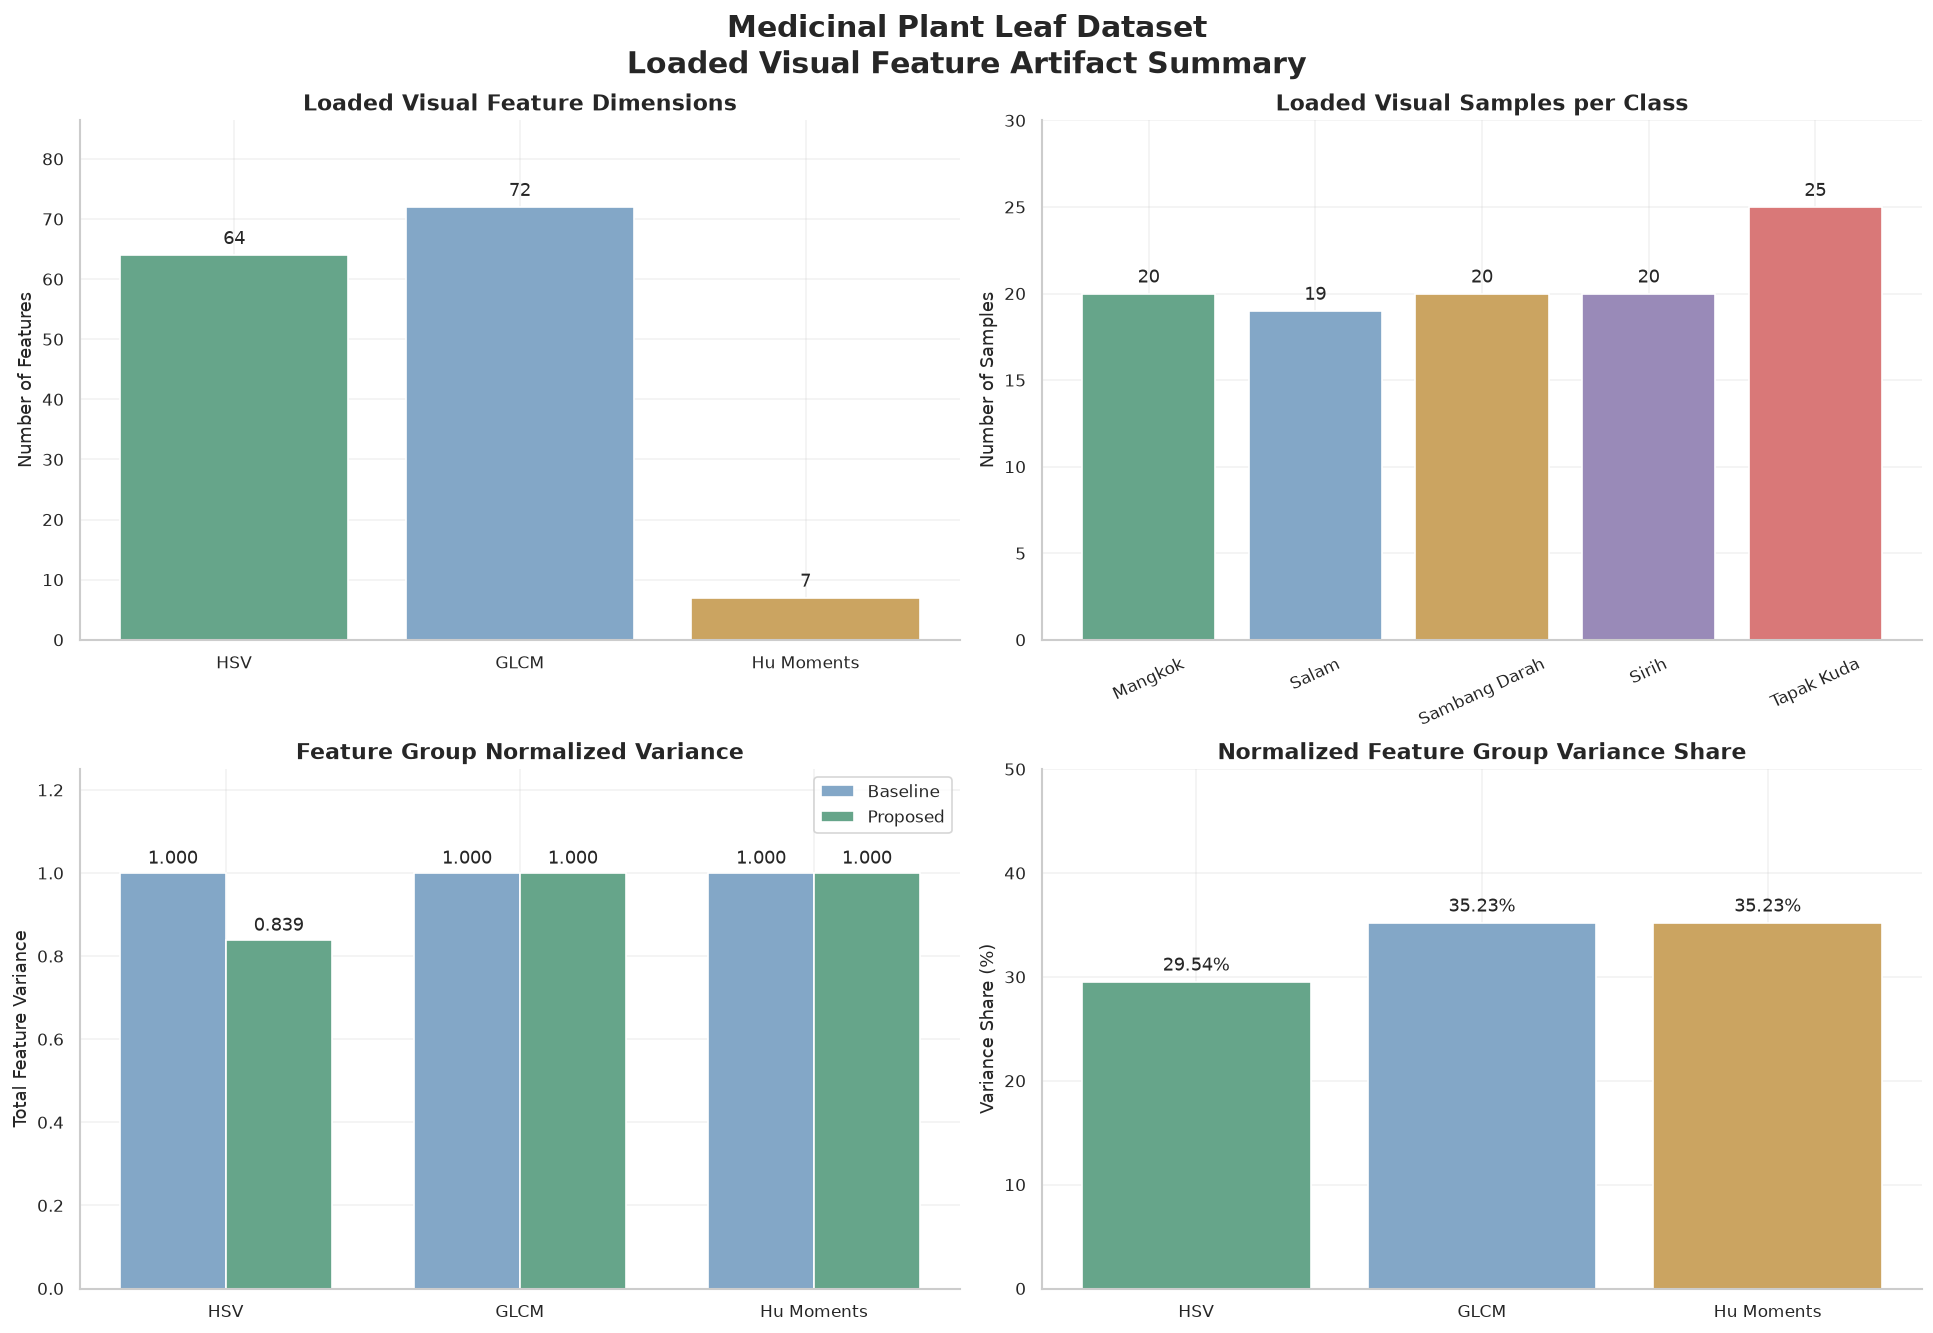

[SAVED] 104_loaded_visual_feature_summary.png


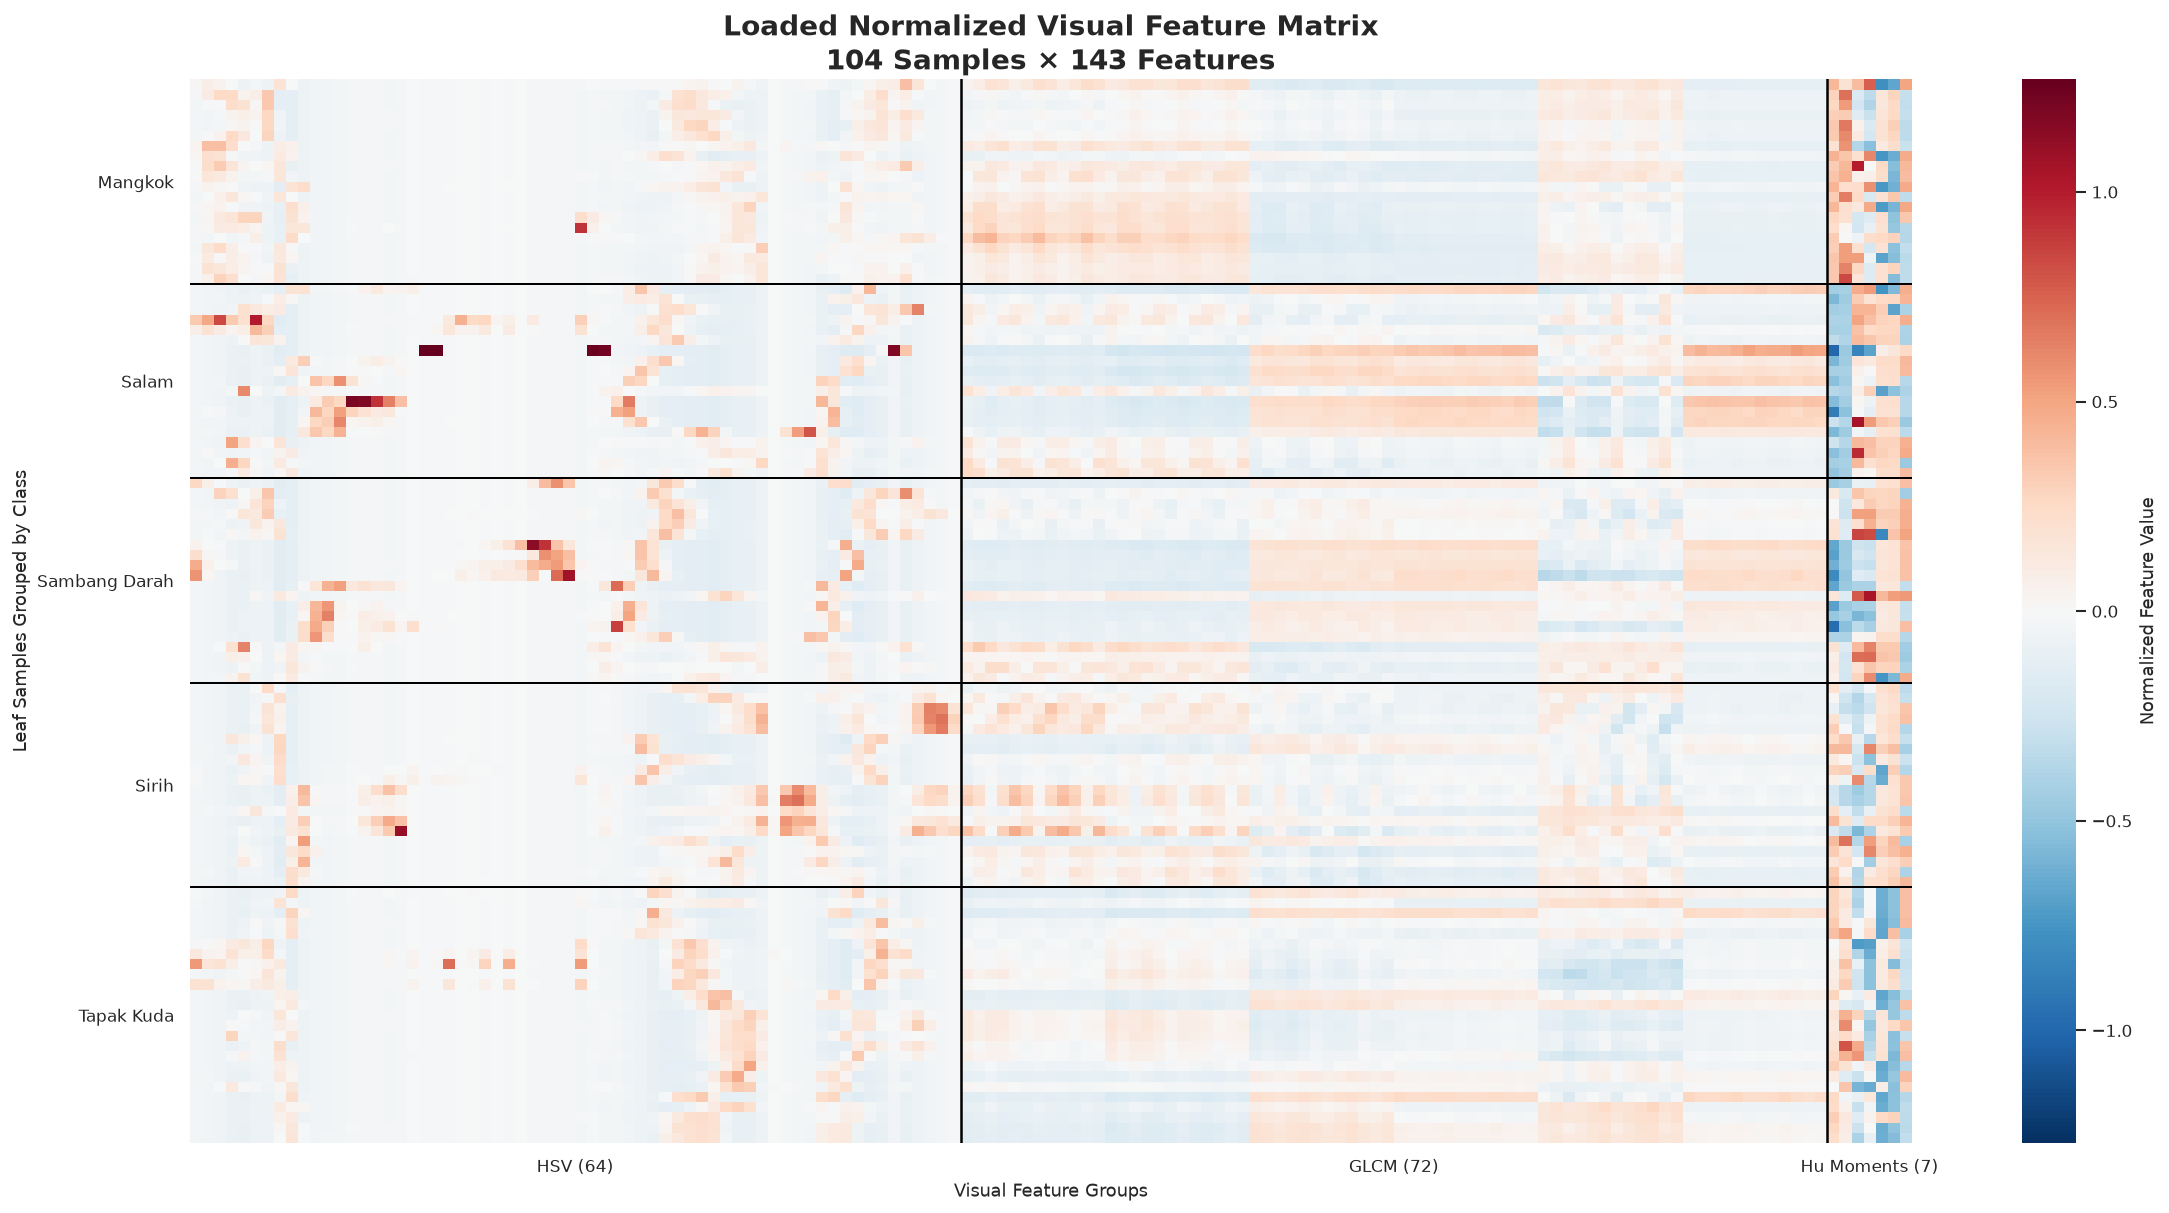

[SAVED] 105_loaded_visual_feature_matrix.png

15. VISUAL LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total visual artifacts,14
1,Verified visual artifacts,14
2,Loaded NumPy arrays,8
3,Loaded visual normalizers,2
4,Total samples,104
5,Total classes,5
6,HSV feature dimension,64
7,GLCM feature dimension,72
8,Hu Moments feature dimension,7
9,Total visual feature dimension,143



16. SAVING VISUAL LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 358_visual_artifact_integrity.csv
[SAVED] 359_loaded_visual_matrix_summary.csv
[SAVED] 360_visual_source_sample_alignment.csv
[SAVED] 361_visual_normalization_reconstruction.csv
[SAVED] 362_loaded_visual_group_summary.csv
[SAVED] 363_loaded_visual_class_summary.csv
[SAVED] 364_loaded_visual_review_summary.csv
[SAVED] 365_visual_loading_validation.csv
[SAVED] 366_visual_artifact_loading_times.csv
[SAVED] 367_visual_loading_summary.csv

FINAL VISUAL FEATURE LOADING SUMMARY

ARTIFACT INFORMATION
----------------------------------------------------------------------
Visual artifacts verified : 14/14
Loaded NumPy arrays       : 8
Loaded normalizers        : 2

VISUAL FEATURE DIMENSIONS
----------------------------------------------------------------------
HSV features        : (104, 64)
GLCM features       : (104, 72)
Hu Moments features : (104, 7)
Raw visual matrix   : (104, 14

In [5]:
# ==================================================
# CELL 4 - LOAD VISUAL FEATURE ARTIFACTS
# ==================================================

print("MULTIMODAL FUSION - LOAD VISUAL FEATURE ARTIFACTS")
print("=" * 70)

VISUAL_FEATURE_LOADING_COMPLETED = False
VISUAL_FEATURES_LOADED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert FUSION_LIBRARIES_IMPORTED is True

assert FUSION_PATH_CONFIGURATION_COMPLETED is True, (
    "Run Cell 3 - Path Configuration first."
)

assert fusion_path_validation_df["passed"].all()

print("[PASS] Previous processing stages validated.")


# ==================================================
# 2. VISUAL FEATURE CONFIGURATION
# ==================================================

EXPECTED_VISUAL_SAMPLES = 104

EXPECTED_VISUAL_DIMENSION = 143

VISUAL_LOADING_TOLERANCE = 1e-10

VISUAL_HSV_SD_FLOOR = 0.001

VISUAL_FEATURE_GROUP_DIMENSIONS = {
    "HSV": 64,
    "GLCM": 72,
    "Hu Moments": 7
}

VISUAL_FEATURE_GROUP_ORDER = [
    "HSV",
    "GLCM",
    "Hu Moments"
]

VISUAL_FEATURE_GROUP_SLICES = {
    "HSV": slice(0, 64),
    "GLCM": slice(64, 136),
    "Hu Moments": slice(136, 143)
}

VISUAL_LOADING_SCOPE = (
    "Full Dataset - Gallery Development"
)

visual_loading_validation_records = []
visual_loading_figure_paths = []

print("\n1. VISUAL FEATURE CONFIGURATION")
print("-" * 70)

print(f"Expected samples   : {EXPECTED_VISUAL_SAMPLES}")
print(f"Expected dimension : {EXPECTED_VISUAL_DIMENSION}")
print(f"HSV SD floor       : {VISUAL_HSV_SD_FLOOR}")
print(f"Numerical tolerance: {VISUAL_LOADING_TOLERANCE}")
print(f"Loading scope      : {VISUAL_LOADING_SCOPE}")


# ==================================================
# 3. HELPER FUNCTIONS
# ==================================================

def register_visual_loading_check(
    category,
    check_name,
    passed
):

    visual_loading_validation_records.append({
        "category": category,
        "validation_check": check_name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def to_clean_string_array(values):

    # Convert any input (object/list/Series) into a
    # trimmed NumPy unicode array (dtype "<U...").
    # np.char functions in NumPy 2.x reject object arrays.

    return (
        pd.Series(np.asarray(values).ravel())
        .astype(str)
        .str.strip()
        .to_numpy(dtype=str)
    )


def all_nonempty_strings(values):

    return bool(
        (pd.Series(np.asarray(values).ravel())
         .astype(str)
         .str.strip() != "").all()
    )


def calculate_artifact_sha256(file_path):

    checksum = hashlib.sha256()

    with open(file_path, "rb") as file:

        for block in iter(
            lambda: file.read(65536),
            b""
        ):
            checksum.update(block)

    return checksum.hexdigest()


def read_fusion_json(file_path):

    with open(
        file_path,
        "r",
        encoding="utf-8-sig"
    ) as file:

        return json.load(file)


def save_visual_loading_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_loading_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 4. LOAD VISUAL ARTIFACT MANIFEST
# ==================================================

# Prefer the CSV manifest generated in Notebook 03.

if VISUAL_MANIFEST_CSV_PATH.is_file():

    loaded_visual_manifest_df = pd.read_csv(
        VISUAL_MANIFEST_CSV_PATH,
        dtype={
            "filename": str,
            "relative_path": str,
            "sha256": str
        },
        keep_default_na=False
    )

    visual_manifest_source = VISUAL_MANIFEST_CSV_PATH

else:

    # Support JSON manifests containing artifact records.

    visual_manifest_payload = read_fusion_json(
        VISUAL_MANIFEST_JSON_PATH
    )

    def extract_manifest_records(node):

        records = []

        if isinstance(node, list):

            for item in node:
                records.extend(
                    extract_manifest_records(item)
                )

        elif isinstance(node, dict):

            if {
                "filename",
                "sha256",
                "size_bytes"
            }.issubset(node):

                records.append(node)

            else:

                for value in node.values():
                    records.extend(
                        extract_manifest_records(value)
                    )

        return records

    loaded_visual_manifest_df = pd.DataFrame(
        extract_manifest_records(
            visual_manifest_payload
        )
    )

    visual_manifest_source = VISUAL_MANIFEST_JSON_PATH


required_manifest_columns = {
    "filename",
    "size_bytes",
    "sha256"
}

assert required_manifest_columns.issubset(
    loaded_visual_manifest_df.columns
), "Unsupported visual manifest structure."

assert loaded_visual_manifest_df[
    "filename"
].is_unique

visual_manifest_index = (
    loaded_visual_manifest_df
    .set_index("filename")
)

expected_visual_filenames = {
    path.name
    for path in VISUAL_ARTIFACT_PATHS.values()
}

register_visual_loading_check(
    "Manifest",
    "All expected visual artifacts listed",
    expected_visual_filenames.issubset(
        set(visual_manifest_index.index)
    )
)

assert expected_visual_filenames.issubset(
    set(visual_manifest_index.index)
), "Some visual artifacts are absent from the manifest."

print("\n2. VISUAL ARTIFACT MANIFEST")
print("-" * 70)

print(f"Manifest source: {visual_manifest_source.name}")
print(f"Manifest records: {len(loaded_visual_manifest_df)}")

display(
    loaded_visual_manifest_df[
        ["filename", "size_bytes", "sha256"]
    ]
)


# ==================================================
# 5. VERIFY ARTIFACT CHECKSUMS BEFORE LOADING
# ==================================================

visual_artifact_integrity_records = []

for artifact_name, file_path in (
    VISUAL_ARTIFACT_PATHS.items()
):

    manifest_record = visual_manifest_index.loc[
        file_path.name
    ]

    expected_size = int(
        manifest_record["size_bytes"]
    )

    expected_checksum = str(
        manifest_record["sha256"]
    ).strip().lower()

    exists = file_path.is_file()

    actual_size = (
        file_path.stat().st_size
        if exists
        else 0
    )

    actual_checksum = (
        calculate_artifact_sha256(file_path)
        if exists
        else ""
    )

    size_match = (
        exists
        and actual_size == expected_size
    )

    checksum_match = (
        exists
        and actual_checksum == expected_checksum
    )

    passed = (
        exists
        and size_match
        and checksum_match
    )

    visual_artifact_integrity_records.append({
        "artifact": artifact_name,
        "filename": file_path.name,
        "expected_size_bytes": expected_size,
        "actual_size_bytes": actual_size,
        "expected_sha256": expected_checksum,
        "actual_sha256": actual_checksum,
        "file_exists": exists,
        "size_match": size_match,
        "checksum_match": checksum_match,
        "passed": passed
    })

    register_visual_loading_check(
        "Artifact Integrity",
        f"{file_path.name} file size and checksum",
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{file_path.name}"
    )


visual_artifact_integrity_df = pd.DataFrame(
    visual_artifact_integrity_records
)

visual_artifact_integrity_df.to_csv(
    METRICS_DIR / "358_visual_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_artifact_integrity_df["passed"].all(), (
    visual_artifact_integrity_df.loc[
        ~visual_artifact_integrity_df["passed"]
    ].to_string(index=False)
)

print("\n[PASS] All visual artifact checksums verified.")


# ==================================================
# 6. LOAD VISUAL NUMPY ARRAYS
# ==================================================

visual_array_keys = [
    "hsv_features",
    "glcm_features",
    "hu_features",
    "hu_raw_moments",
    "raw_features",
    "baseline_features",
    "normalized_features",
    "sample_ids"
]

loaded_visual_arrays = {}
visual_loading_time_records = []

print("\n3. LOADING VISUAL NUMPY ARRAYS")
print("-" * 70)

for artifact_name in visual_array_keys:

    start_time = time.perf_counter()

    array = np.load(
        VISUAL_ARTIFACT_PATHS[artifact_name],
        allow_pickle=False
    )

    loading_time_ms = (
        time.perf_counter() - start_time
    ) * 1000

    loaded_visual_arrays[artifact_name] = array

    visual_loading_time_records.append({
        "artifact": artifact_name,
        "filename": (
            VISUAL_ARTIFACT_PATHS[
                artifact_name
            ].name
        ),
        "loading_time_ms": loading_time_ms,
        "array_shape": str(array.shape),
        "dtype": str(array.dtype)
    })

    print(
        f"[LOADED] {artifact_name}: "
        f"{array.shape}"
    )


# ==================================================
# 7. CREATE MAIN VISUAL FEATURE VARIABLES
# ==================================================

loaded_hsv_features = (
    loaded_visual_arrays["hsv_features"]
)

loaded_glcm_features = (
    loaded_visual_arrays["glcm_features"]
)

loaded_hu_features = (
    loaded_visual_arrays["hu_features"]
)

loaded_hu_raw_moments = (
    loaded_visual_arrays["hu_raw_moments"]
)

loaded_visual_raw_features = (
    loaded_visual_arrays["raw_features"]
)

loaded_visual_baseline_features = (
    loaded_visual_arrays["baseline_features"]
)

loaded_visual_normalized_features = (
    loaded_visual_arrays["normalized_features"]
)

loaded_visual_sample_ids = to_clean_string_array(
    loaded_visual_arrays["sample_ids"]
)

# Main representation for subsequent fusion.

visual_features = (
    loaded_visual_normalized_features
)

visual_sample_ids = (
    loaded_visual_sample_ids
)

visual_n_samples = len(
    loaded_visual_sample_ids
)

VISUAL_FEATURE_DIM = (
    visual_features.shape[1]
)


# ==================================================
# 8. VALIDATE MATRIX DIMENSIONS AND VALUES
# ==================================================

visual_expected_shapes = {
    "hsv_features": (104, 64),
    "glcm_features": (104, 72),
    "hu_features": (104, 7),
    "hu_raw_moments": (104, 7),
    "raw_features": (104, 143),
    "baseline_features": (104, 143),
    "normalized_features": (104, 143)
}

visual_matrix_records = []

for artifact_name, expected_shape in (
    visual_expected_shapes.items()
):

    matrix = loaded_visual_arrays[
        artifact_name
    ]

    correct_shape = (
        matrix.shape == expected_shape
    )

    correct_dtype = (
        matrix.dtype == np.float64
    )

    finite_values = bool(
        np.isfinite(matrix).all()
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} correct dimensions",
        correct_shape
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} float64 dtype",
        correct_dtype
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} finite values",
        finite_values
    )

    visual_matrix_records.append({
        "artifact": artifact_name,
        "number_of_samples": matrix.shape[0],
        "feature_dimension": matrix.shape[1],
        "matrix_shape": str(matrix.shape),
        "dtype": str(matrix.dtype),
        "minimum_value": float(matrix.min()),
        "maximum_value": float(matrix.max()),
        "mean_value": float(matrix.mean()),
        "std_value": float(matrix.std()),
        "nan_values": int(np.isnan(matrix).sum()),
        "infinite_values": int(np.isinf(matrix).sum()),
        "memory_kib": matrix.nbytes / 1024,
        "passed": (
            correct_shape
            and correct_dtype
            and finite_values
        )
    })


visual_loaded_matrix_summary_df = pd.DataFrame(
    visual_matrix_records
)

print("\n4. VISUAL MATRIX VALIDATION")
print("-" * 70)

display(
    visual_loaded_matrix_summary_df.round(6)
)

assert visual_loaded_matrix_summary_df[
    "passed"
].all()


# ==================================================
# 9. VALIDATE SAMPLE IDENTITIES
# ==================================================

visual_id_checks = {

    "Sample ID array is one dimensional":
        loaded_visual_sample_ids.ndim == 1,

    "Expected sample ID count":
        visual_n_samples == EXPECTED_VISUAL_SAMPLES,

    "Sample IDs are unique":
        len(np.unique(loaded_visual_sample_ids))
        == visual_n_samples,

    "Sample IDs are nonempty":
        all_nonempty_strings(
            loaded_visual_sample_ids
        ),

    "Sample IDs contain no invalid placeholders":
        not pd.Series(loaded_visual_sample_ids)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["nan", "none", "null"])
        .any()
}

for check_name, passed in visual_id_checks.items():

    register_visual_loading_check(
        "Sample Identity",
        check_name,
        passed
    )

assert all(visual_id_checks.values()), (
    "Invalid visual sample IDs detected."
)

print("\n5. VISUAL SAMPLE IDENTITIES")
print("-" * 70)

print(f"Total sample IDs  : {visual_n_samples}")

print(
    "Unique sample IDs :",
    len(np.unique(loaded_visual_sample_ids))
)

print("First five IDs:")

display(loaded_visual_sample_ids[:5])


# ==================================================
# 10. LOAD VISUAL METADATA
# ==================================================

loaded_visual_metadata_df = pd.read_csv(
    VISUAL_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False,
    float_precision="round_trip"
)

loaded_processed_metadata_df = pd.read_csv(
    PROCESSED_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False,
    float_precision="round_trip"
)

required_visual_metadata_columns = {
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path",
    "validation_status"
}

assert required_visual_metadata_columns.issubset(
    loaded_visual_metadata_df.columns
), (
    "Required visual metadata columns missing."
)

assert {
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path",
    "multimodal_valid",
    "final_dataset_status"
}.issubset(
    loaded_processed_metadata_df.columns
)

assert loaded_visual_metadata_df[
    "sample_id"
].is_unique

assert loaded_processed_metadata_df[
    "sample_id"
].is_unique

assert len(loaded_visual_metadata_df) == visual_n_samples

assert np.array_equal(
    loaded_visual_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str),
    loaded_visual_sample_ids
), "Visual metadata row order mismatch."

assert set(
    loaded_visual_sample_ids
) == set(
    loaded_processed_metadata_df["sample_id"]
), "Source and visual sample coverage mismatch."

# Align source metadata only.
# The saved feature matrix order remains unchanged.

visual_source_aligned_df = (
    loaded_processed_metadata_df
    .set_index("sample_id")
    .loc[loaded_visual_sample_ids]
    .reset_index()
)

loaded_visual_labels = to_clean_string_array(
    loaded_visual_metadata_df["kelas"]
)

visual_labels = loaded_visual_labels

visual_class_names = sorted(
    np.unique(visual_labels)
)

# Identify the saved row-index column.

visual_row_index_column = next(
    (
        column
        for column in [
            "feature_row_index",
            "visual_feature_row",
            "feature_row",
            "row_index",
            "sample_index"
        ]
        if column in loaded_visual_metadata_df.columns
    ),
    None
)

assert visual_row_index_column is not None, (
    "Saved visual feature row-index column not found."
)

saved_row_indices = pd.to_numeric(
    loaded_visual_metadata_df[
        visual_row_index_column
    ],
    errors="raise"
).to_numpy()

register_visual_loading_check(
    "Metadata Alignment",
    "Visual row indices sequential",
    np.array_equal(
        saved_row_indices,
        np.arange(visual_n_samples)
    )
)

print("\n6. VISUAL METADATA")
print("-" * 70)

print(
    "Visual metadata shape:",
    loaded_visual_metadata_df.shape
)

display(
    loaded_visual_metadata_df[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ].head(10)
)


# ==================================================
# 11. VALIDATE METADATA ALIGNMENT
# ==================================================

visual_sample_alignment_df = pd.DataFrame({
    "row_index": np.arange(visual_n_samples),
    "sample_id": loaded_visual_sample_ids,
    "kelas": visual_labels
})

visual_identity_columns = [
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path"
]

visual_alignment_columns = []

for column in visual_identity_columns:

    visual_values = (
        loaded_visual_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    source_values = (
        visual_source_aligned_df[
            column
        ].astype(str).to_numpy()
    )

    match_column = f"{column}_match"

    visual_sample_alignment_df[
        match_column
    ] = (
        visual_values == source_values
    )

    visual_alignment_columns.append(
        match_column
    )

    register_visual_loading_check(
        "Metadata Alignment",
        f"{column} matches processed metadata",
        visual_sample_alignment_df[
            match_column
        ].all()
    )


visual_sample_alignment_df[
    "alignment_passed"
] = visual_sample_alignment_df[
    visual_alignment_columns
].all(axis=1)

register_visual_loading_check(
    "Metadata Alignment",
    "All visual samples match source metadata",
    visual_sample_alignment_df[
        "alignment_passed"
    ].all()
)

assert visual_sample_alignment_df[
    "alignment_passed"
].all()

print("[PASS] Visual metadata alignment validated.")


# ==================================================
# 12. LOAD VISUAL FEATURE INDEX AND CONFIGURATION
# ==================================================

loaded_visual_feature_index_df = pd.read_csv(
    VISUAL_ARTIFACT_PATHS["feature_index"],
    encoding="utf-8-sig",
    keep_default_na=False
)

loaded_visual_feature_names_payload = read_fusion_json(
    VISUAL_ARTIFACT_PATHS["feature_names"]
)

loaded_visual_config = read_fusion_json(
    VISUAL_ARTIFACT_PATHS["configuration"]
)

# Clean CSV header names.
loaded_visual_feature_index_df.columns = (
    loaded_visual_feature_index_df.columns
    .astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

print("\n7. VISUAL FEATURE INDEX")
print("-" * 70)

print(
    "Original CSV columns:",
    loaded_visual_feature_index_df.columns.tolist()
)

print(
    "Total feature records:",
    len(loaded_visual_feature_index_df)
)

# --------------------------------------------------
# A. Detect column names based on actual CSV schema
# --------------------------------------------------

def find_existing_column(dataframe, candidates):

    lookup = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        match = lookup.get(candidate.lower())

        if match is not None:
            return match

    return None


index_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_index",
        "global_feature_index",
        "global_index",
        "column_index",
        "feature_position",
        "index",
        "idx"
    ]
)

name_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_name",
        "feature",
        "name",
        "feature_label",
        "feature_id",
        "feature_description"
    ]
)

group_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_group",
        "group",
        "feature_type",
        "feature_category"
    ]
)

print("Detected index column:", index_column)
print("Detected name column :", name_column)
print("Detected group column:", group_column)

# Do not invent feature names or indices.
# Report the real schema if it is not recognized.

if index_column is None or name_column is None:

    display(
        loaded_visual_feature_index_df.head(5)
    )

    raise ValueError(
        "Visual feature index CSV schema is not recognized. "
        f"Available columns: "
        f"{loaded_visual_feature_index_df.columns.tolist()}"
    )

# --------------------------------------------------
# B. Standardize column names for subsequent checks
# --------------------------------------------------

rename_columns = {
    index_column: "feature_index",
    name_column: "feature_name"
}

if group_column is not None:

    rename_columns[group_column] = "feature_group"

loaded_visual_feature_index_df = (
    loaded_visual_feature_index_df.rename(
        columns=rename_columns
    )
)

# Validate row count.

assert len(
    loaded_visual_feature_index_df
) == EXPECTED_VISUAL_DIMENSION, (
    "Feature index row count does not match "
    "the expected 143 visual features."
)

# --------------------------------------------------
# C. Validate and normalize feature indices
# --------------------------------------------------

feature_indices = pd.to_numeric(
    loaded_visual_feature_index_df["feature_index"],
    errors="raise"
).to_numpy()

expected_zero_based = np.arange(
    EXPECTED_VISUAL_DIMENSION
)

expected_one_based = np.arange(
    1,
    EXPECTED_VISUAL_DIMENSION + 1
)

if np.array_equal(
    feature_indices,
    expected_zero_based
):

    print("[PASS] Zero-based feature indices detected.")

elif np.array_equal(
    feature_indices,
    expected_one_based
):

    print("[INFO] One-based feature indices detected.")

    # Convert index labels to zero-based positions.
    # The row order is not changed.

    loaded_visual_feature_index_df[
        "feature_index"
    ] = expected_zero_based

else:

    raise ValueError(
        "Feature indices are not sequential "
        "or do not follow the saved column order."
    )

# --------------------------------------------------
# D. Validate feature names
# --------------------------------------------------

# FIX: use dtype=str so the array is "<U..." rather
# than object dtype (np.char rejects object arrays).

loaded_visual_feature_names = to_clean_string_array(
    loaded_visual_feature_index_df["feature_name"]
)

assert len(
    np.unique(loaded_visual_feature_names)
) == EXPECTED_VISUAL_DIMENSION, (
    "Duplicate visual feature names detected."
)

assert all_nonempty_strings(
    loaded_visual_feature_names
), "Empty visual feature names detected."

# Normalize recognized group labels without
# changing the feature-group sequence.

if "feature_group" in loaded_visual_feature_index_df:

    normalized_groups = (
        loaded_visual_feature_index_df[
            "feature_group"
        ]
        .astype(str)
        .str.strip()
    )

    group_aliases = {
        "hsv": "HSV",
        "glcm": "GLCM",
        "hu": "Hu Moments",
        "hu moments": "Hu Moments",
        "hu_moments": "Hu Moments",
        "humoments": "Hu Moments"
    }

    loaded_visual_feature_index_df[
        "feature_group"
    ] = normalized_groups.map(
        lambda value: group_aliases.get(
            value.lower(),
            value
        )
    )

# --------------------------------------------------
# E. Register validation results
# --------------------------------------------------

register_visual_loading_check(
    "Feature Index",
    "Visual feature indices sequential",
    np.array_equal(
        loaded_visual_feature_index_df[
            "feature_index"
        ].to_numpy(),
        expected_zero_based
    )
)

register_visual_loading_check(
    "Feature Index",
    "Visual feature names unique",
    len(np.unique(
        loaded_visual_feature_names
    )) == EXPECTED_VISUAL_DIMENSION
)

register_visual_loading_check(
    "Feature Index",
    "Visual feature names nonempty",
    all_nonempty_strings(
        loaded_visual_feature_names
    )
)

print("\nStandardized CSV columns:")
print(
    loaded_visual_feature_index_df.columns.tolist()
)

display(
    loaded_visual_feature_index_df.head(10)
)

print("[PASS] Visual feature index loaded and validated.")


# ==================================================
# 13. VALIDATE FEATURE NAME ORDER
# ==================================================

# Support either a single complete feature-name list
# or separate lists for HSV, GLCM, and Hu Moments.

def collect_feature_name_lists(node):

    results = []

    if isinstance(node, list):

        if node and all(
            isinstance(item, str)
            for item in node
        ):

            results.append(node)

        else:

            for item in node:

                results.extend(
                    collect_feature_name_lists(item)
                )

    elif isinstance(node, dict):

        for value in node.values():

            results.extend(
                collect_feature_name_lists(value)
            )

    return results


visual_name_lists = [
    [str(name).strip() for name in names]
    for names in collect_feature_name_lists(
        loaded_visual_feature_names_payload
    )
]

expected_names_list = (
    loaded_visual_feature_names.tolist()
)

complete_name_order_match = any(
    names == expected_names_list
    for names in visual_name_lists
)

group_name_order_match = all(

    any(
        names == expected_names_list[
            VISUAL_FEATURE_GROUP_SLICES[group_name]
        ]

        for names in visual_name_lists
    )

    for group_name in VISUAL_FEATURE_GROUP_ORDER
)

register_visual_loading_check(
    "Feature Index",
    "Feature-name JSON matches feature index",
    complete_name_order_match
    or group_name_order_match
)

register_visual_loading_check(
    "Feature Index",
    "Feature configuration loaded",
    isinstance(loaded_visual_config, dict)
    and len(loaded_visual_config) > 0
)

if "feature_group" in (
    loaded_visual_feature_index_df.columns
):

    expected_group_sequence = np.repeat(
        VISUAL_FEATURE_GROUP_ORDER,
        [64, 72, 7]
    )

    actual_group_sequence = (
        loaded_visual_feature_index_df[
            "feature_group"
        ].to_numpy(dtype=str)
    )

    register_visual_loading_check(
        "Feature Index",
        "Feature group order preserved",
        np.array_equal(
            actual_group_sequence,
            expected_group_sequence
        )
    )


print("\n7. VISUAL FEATURE INDEX")
print("-" * 70)

print(
    "Feature names:",
    len(loaded_visual_feature_names)
)

display(
    loaded_visual_feature_index_df.head(10)
)


# ==================================================
# 14. LOAD SAVED NORMALIZERS
# ==================================================

# Only load locally generated, trusted Joblib files.
# The manifest checks were completed before this stage.

loaded_visual_normalizer = joblib.load(
    VISUAL_ARTIFACT_PATHS["normalizer"]
)

loaded_baseline_visual_normalizer = joblib.load(
    VISUAL_ARTIFACT_PATHS["baseline_normalizer"]
)

register_visual_loading_check(
    "Normalizer Loading",
    "Main visual normalizer loaded",
    loaded_visual_normalizer is not None
)

register_visual_loading_check(
    "Normalizer Loading",
    "Baseline visual normalizer loaded",
    loaded_baseline_visual_normalizer is not None
)

print("\n8. LOADED VISUAL NORMALIZERS")
print("-" * 70)

print(
    "Main normalizer type:",
    type(loaded_visual_normalizer).__name__
)

print(
    "Baseline normalizer type:",
    type(loaded_baseline_visual_normalizer).__name__
)

if isinstance(loaded_visual_normalizer, dict):

    print(
        "Main normalizer keys:",
        list(loaded_visual_normalizer.keys())
    )

if isinstance(
    loaded_baseline_visual_normalizer,
    dict
):

    print(
        "Baseline normalizer keys:",
        list(
            loaded_baseline_visual_normalizer.keys()
        )
    )


# ==================================================
# 15. RECONSTRUCT RAW FEATURE CONCATENATION
# ==================================================

reconstructed_visual_raw_features = np.hstack([
    loaded_hsv_features,
    loaded_glcm_features,
    loaded_hu_features
])

visual_raw_reconstruction_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_raw_features
            - loaded_visual_raw_features
        )
    )
)

register_visual_loading_check(
    "Feature Reconstruction",
    "Raw feature concatenation exactly preserved",
    np.array_equal(
        reconstructed_visual_raw_features,
        loaded_visual_raw_features
    )
)

print("\n9. RAW FEATURE RECONSTRUCTION")
print("-" * 70)

print(
    "Reconstructed raw shape:",
    reconstructed_visual_raw_features.shape
)

print(
    "Maximum reconstruction difference:",
    f"{visual_raw_reconstruction_difference:.3e}"
)


# ==================================================
# 16. VERIFY NORMALIZATION MATHEMATICALLY
# ==================================================

# Independently reproduce the documented normalization
# formulas from Notebook 03.
#
# No saved normalizer is refitted or modified.
# Reconstructed arrays are used only for verification.

visual_raw_group_matrices = {
    "HSV": loaded_hsv_features,
    "GLCM": loaded_glcm_features,
    "Hu Moments": loaded_hu_features
}

visual_reconstructed_baseline_groups = {}

visual_reconstructed_normalized_groups = {}

visual_normalization_records = []

for group_name in VISUAL_FEATURE_GROUP_ORDER:

    raw_group = visual_raw_group_matrices[
        group_name
    ]

    dimension = raw_group.shape[1]

    feature_mean = raw_group.mean(axis=0)

    feature_std = raw_group.std(
        axis=0,
        ddof=0
    )

    constant_mask = feature_std == 0

    baseline_scale = np.where(
        constant_mask,
        1.0,
        feature_std
    )

    proposed_scale = baseline_scale.copy()

    floor_mask = np.zeros(
        dimension,
        dtype=bool
    )

    if group_name == "HSV":

        floor_mask = (
            (feature_std < VISUAL_HSV_SD_FLOOR)
            & ~constant_mask
        )

        proposed_scale[floor_mask] = (
            VISUAL_HSV_SD_FLOOR
        )

    # Group balancing.

    group_weight = 1.0 / np.sqrt(
        dimension
    )

    baseline_group = (
        (raw_group - feature_mean)
        / baseline_scale
    ) * group_weight

    proposed_group = (
        (raw_group - feature_mean)
        / proposed_scale
    ) * group_weight

    group_slice = (
        VISUAL_FEATURE_GROUP_SLICES[
            group_name
        ]
    )

    saved_baseline_group = (
        loaded_visual_baseline_features[
            :, group_slice
        ]
    )

    saved_normalized_group = (
        loaded_visual_normalized_features[
            :, group_slice
        ]
    )

    baseline_difference = float(
        np.max(
            np.abs(
                baseline_group
                - saved_baseline_group
            )
        )
    )

    proposed_difference = float(
        np.max(
            np.abs(
                proposed_group
                - saved_normalized_group
            )
        )
    )

    register_visual_loading_check(
        "Normalization Reconstruction",
        f"{group_name} baseline normalization consistent",
        baseline_difference <= VISUAL_LOADING_TOLERANCE
    )

    register_visual_loading_check(
        "Normalization Reconstruction",
        f"{group_name} proposed normalization consistent",
        proposed_difference <= VISUAL_LOADING_TOLERANCE
    )

    visual_reconstructed_baseline_groups[
        group_name
    ] = baseline_group

    visual_reconstructed_normalized_groups[
        group_name
    ] = proposed_group

    visual_normalization_records.append({
        "feature_group": group_name,
        "feature_dimension": dimension,
        "group_weight": group_weight,
        "constant_features": int(constant_mask.sum()),
        "sd_floor_adjusted_features": int(
            floor_mask.sum()
        ),
        "raw_total_variance": float(
            raw_group.var(axis=0).sum()
        ),
        "baseline_total_variance": float(
            saved_baseline_group.var(axis=0).sum()
        ),
        "normalized_total_variance": float(
            saved_normalized_group.var(axis=0).sum()
        ),
        "baseline_max_difference": baseline_difference,
        "normalized_max_difference": proposed_difference
    })


visual_normalization_reconstruction_df = pd.DataFrame(
    visual_normalization_records
)

print("\n10. NORMALIZATION RECONSTRUCTION")
print("-" * 70)

display(
    visual_normalization_reconstruction_df.round(8)
)


# ==================================================
# 17. VALIDATE COMPLETE NORMALIZED MATRICES
# ==================================================

reconstructed_visual_baseline_features = np.hstack([

    visual_reconstructed_baseline_groups[
        group_name
    ]

    for group_name in VISUAL_FEATURE_GROUP_ORDER

])

reconstructed_visual_normalized_features = np.hstack([

    visual_reconstructed_normalized_groups[
        group_name
    ]

    for group_name in VISUAL_FEATURE_GROUP_ORDER

])

visual_baseline_max_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_baseline_features
            - loaded_visual_baseline_features
        )
    )
)

visual_normalized_max_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_normalized_features
            - loaded_visual_normalized_features
        )
    )
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Complete baseline matrix reproduced",
    visual_baseline_max_difference
    <= VISUAL_LOADING_TOLERANCE
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Complete normalized matrix reproduced",
    visual_normalized_max_difference
    <= VISUAL_LOADING_TOLERANCE
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Normalized features centered around zero",
    np.allclose(
        visual_features.mean(axis=0),
        0,
        atol=VISUAL_LOADING_TOLERANCE,
        rtol=0
    )
)

print(
    "Baseline maximum difference:",
    f"{visual_baseline_max_difference:.3e}"
)

print(
    "Normalized maximum difference:",
    f"{visual_normalized_max_difference:.3e}"
)


# ==================================================
# 18. ANALYZE VISUAL FEATURE GROUPS
# ==================================================

visual_group_statistics_records = []

for group_name in VISUAL_FEATURE_GROUP_ORDER:

    group_slice = VISUAL_FEATURE_GROUP_SLICES[
        group_name
    ]

    group_matrix = visual_features[
        :, group_slice
    ]

    group_variance = group_matrix.var(
        axis=0
    )

    visual_group_statistics_records.append({
        "feature_group": group_name,
        "number_of_samples": group_matrix.shape[0],
        "feature_dimension": group_matrix.shape[1],
        "minimum_value": float(group_matrix.min()),
        "maximum_value": float(group_matrix.max()),
        "mean_value": float(group_matrix.mean()),
        "std_value": float(group_matrix.std()),
        "total_variance": float(group_variance.sum()),
        "constant_features": int(
            (np.ptp(group_matrix, axis=0) == 0).sum()
        ),
        "nan_values": int(
            np.isnan(group_matrix).sum()
        ),
        "infinite_values": int(
            np.isinf(group_matrix).sum()
        )
    })


visual_loaded_group_summary_df = pd.DataFrame(
    visual_group_statistics_records
)

total_visual_variance = (
    visual_loaded_group_summary_df[
        "total_variance"
    ].sum()
)

assert total_visual_variance > 0

visual_loaded_group_summary_df[
    "variance_share_percent"
] = (
    visual_loaded_group_summary_df[
        "total_variance"
    ]
    / total_visual_variance
    * 100
)

register_visual_loading_check(
    "Feature Groups",
    "Feature dimensions reconcile",
    visual_loaded_group_summary_df[
        "feature_dimension"
    ].sum() == EXPECTED_VISUAL_DIMENSION
)

register_visual_loading_check(
    "Feature Groups",
    "Feature group variance shares reconcile",
    np.isclose(
        visual_loaded_group_summary_df[
            "variance_share_percent"
        ].sum(),
        100.0,
        atol=VISUAL_LOADING_TOLERANCE
    )
)

print("\n11. VISUAL FEATURE GROUP SUMMARY")
print("-" * 70)

display(
    visual_loaded_group_summary_df.round(6)
)


# ==================================================
# 19. ANALYZE CLASS DISTRIBUTION
# ==================================================

visual_loaded_class_summary_df = (
    pd.Series(
        visual_labels,
        name="kelas"
    )
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

visual_loaded_class_summary_df[
    "percentage"
] = (
    visual_loaded_class_summary_df[
        "number_of_samples"
    ]
    / visual_n_samples
    * 100
)

expected_visual_class_counts = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

actual_visual_class_counts = dict(zip(
    visual_loaded_class_summary_df["kelas"],
    visual_loaded_class_summary_df["number_of_samples"]
))

register_visual_loading_check(
    "Class Distribution",
    "Expected five-class distribution preserved",
    actual_visual_class_counts
    == expected_visual_class_counts
)

print("\n12. VISUAL CLASS DISTRIBUTION")
print("-" * 70)

display(
    visual_loaded_class_summary_df.round(4)
)


# ==================================================
# 20. PRESERVE DATASET REVIEW STATUS
# ==================================================

visual_loaded_review_summary_df = (
    visual_source_aligned_df[
        "final_dataset_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("dataset_status")
    .reset_index(name="number_of_samples")
)

visual_loaded_review_summary_df[
    "percentage"
] = (
    visual_loaded_review_summary_df[
        "number_of_samples"
    ]
    / visual_n_samples
    * 100
)

source_technical_validity = (
    visual_source_aligned_df[
        "multimodal_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

register_visual_loading_check(
    "Dataset Readiness",
    "All source samples technically valid",
    source_technical_validity.all()
)

register_visual_loading_check(
    "Dataset Readiness",
    "Dataset review status counts reconcile",
    visual_loaded_review_summary_df[
        "number_of_samples"
    ].sum() == visual_n_samples
)

print("\n13. DATASET REVIEW STATUS")
print("-" * 70)

display(
    visual_loaded_review_summary_df.round(4)
)

print(
    "[INFO] Manual review flags remain unchanged."
)


# ==================================================
# 21. FINAL VISUAL LOADING VALIDATION
# ==================================================

visual_loading_validation_df = pd.DataFrame(
    visual_loading_validation_records
)

visual_loading_total_checks = len(
    visual_loading_validation_df
)

visual_loading_passed_checks = int(
    visual_loading_validation_df[
        "passed"
    ].sum()
)

visual_loading_failed_checks = (
    visual_loading_total_checks
    - visual_loading_passed_checks
)

visual_loading_validation_df.to_csv(
    METRICS_DIR / "365_visual_loading_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n14. VISUAL FEATURE LOADING VALIDATION")
print("-" * 70)

display(visual_loading_validation_df)

assert visual_loading_validation_df[
    "passed"
].all(), (
    visual_loading_validation_df.loc[
        ~visual_loading_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All visual loading checks passed.")


# ==================================================
# 22. VISUALIZE LOADED VISUAL FEATURE SUMMARY
# ==================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

# A. Feature dimensions.

ax = axes[0, 0]

group_names = (
    visual_loaded_group_summary_df[
        "feature_group"
    ].tolist()
)

group_colors = [
    FEATURE_GROUP_COLORS[name]
    for name in group_names
]

bars = ax.bar(
    group_names,
    visual_loaded_group_summary_df[
        "feature_dimension"
    ],
    color=group_colors
)

ax.bar_label(bars, padding=4)

ax.set_title("Loaded Visual Feature Dimensions")
ax.set_ylabel("Number of Features")
ax.margins(y=0.2)


# B. Class distribution.

ax = axes[0, 1]

bars = ax.bar(
    visual_loaded_class_summary_df["kelas"],
    visual_loaded_class_summary_df[
        "number_of_samples"
    ],
    color=[
        CLASS_COLORS.get(name, "#83A7C7")
        for name in visual_loaded_class_summary_df[
            "kelas"
        ]
    ]
)

ax.bar_label(bars, padding=4)

ax.set_title("Loaded Visual Samples per Class")
ax.set_ylabel("Number of Samples")
ax.tick_params(axis="x", labelrotation=25)
ax.margins(y=0.2)


# C. Baseline vs proposed normalization variance.

ax = axes[1, 0]

positions = np.arange(len(group_names))

bars_baseline = ax.bar(
    positions - 0.18,
    visual_normalization_reconstruction_df[
        "baseline_total_variance"
    ],
    width=0.36,
    color="#83A7C7",
    label="Baseline"
)

bars_proposed = ax.bar(
    positions + 0.18,
    visual_normalization_reconstruction_df[
        "normalized_total_variance"
    ],
    width=0.36,
    color="#66A58A",
    label="Proposed"
)

ax.bar_label(
    bars_baseline,
    fmt="%.3f",
    padding=3
)

ax.bar_label(
    bars_proposed,
    fmt="%.3f",
    padding=3
)

ax.set_xticks(positions)
ax.set_xticklabels(group_names)

ax.set_title("Feature Group Normalized Variance")
ax.set_ylabel("Total Feature Variance")
ax.set_ylim(0, 1.25)
ax.legend()


# D. Variance contribution after normalization.

ax = axes[1, 1]

bars = ax.bar(
    group_names,
    visual_loaded_group_summary_df[
        "variance_share_percent"
    ],
    color=group_colors
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.set_title("Normalized Feature Group Variance Share")
ax.set_ylabel("Variance Share (%)")
ax.set_ylim(0, 50)

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Loaded Visual Feature Artifact Summary",
    fontsize=18,
    fontweight="bold"
)

save_visual_loading_figure(
    fig,
    "104_loaded_visual_feature_summary.png"
)


# ==================================================
# 23. VISUALIZE LOADED VISUAL FEATURE MATRIX
# ==================================================

visual_plot_order = np.argsort(
    visual_labels,
    kind="stable"
)

visual_plot_labels = visual_labels[
    visual_plot_order
]

visual_plot_matrix = visual_features[
    visual_plot_order
]

visual_class_boundaries = np.flatnonzero(
    visual_plot_labels[1:]
    != visual_plot_labels[:-1]
) + 1

visual_class_starts = np.r_[
    0,
    visual_class_boundaries
]

visual_class_ends = np.r_[
    visual_class_boundaries,
    visual_n_samples
]

visual_class_centers = (
    visual_class_starts
    + visual_class_ends
) / 2

# Use symmetric limits around zero.

visual_heatmap_limit = float(
    np.max(np.abs(visual_plot_matrix))
)

fig, ax = plt.subplots(
    figsize=(18, 10),
    constrained_layout=True
)

sns.heatmap(
    visual_plot_matrix,
    cmap="RdBu_r",
    center=0,
    vmin=-visual_heatmap_limit,
    vmax=visual_heatmap_limit,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={
        "label": "Normalized Feature Value"
    },
    ax=ax
)

# Mark visual feature-group boundaries.

for boundary in [64, 136]:

    ax.axvline(
        boundary,
        color="black",
        linewidth=1.5
    )

# Mark class boundaries.

for boundary in visual_class_boundaries:

    ax.axhline(
        boundary,
        color="black",
        linewidth=1.2
    )

ax.set_xticks([
    32,
    100,
    139.5
])

ax.set_xticklabels([
    "HSV (64)",
    "GLCM (72)",
    "Hu Moments (7)"
], rotation=0)

ax.set_yticks(
    visual_class_centers
)

ax.set_yticklabels(
    visual_plot_labels[
        visual_class_starts
    ],
    rotation=0
)

ax.set_xlabel("Visual Feature Groups")
ax.set_ylabel("Leaf Samples Grouped by Class")

ax.set_title(
    "Loaded Normalized Visual Feature Matrix\n"
    f"{visual_n_samples} Samples × "
    f"{VISUAL_FEATURE_DIM} Features",
    fontsize=17,
    fontweight="bold"
)

save_visual_loading_figure(
    fig,
    "105_loaded_visual_feature_matrix.png"
)


# ==================================================
# 24. CREATE VISUAL LOADING SUMMARY
# ==================================================

visual_loading_time_df = pd.DataFrame(
    visual_loading_time_records
)

visual_loading_summary_df = pd.DataFrame([

    ("Total visual artifacts",
     len(VISUAL_ARTIFACT_PATHS)),

    ("Verified visual artifacts",
     int(visual_artifact_integrity_df["passed"].sum())),

    ("Loaded NumPy arrays",
     len(loaded_visual_arrays)),

    ("Loaded visual normalizers", 2),

    ("Total samples", visual_n_samples),

    ("Total classes", len(visual_class_names)),

    ("HSV feature dimension",
     loaded_hsv_features.shape[1]),

    ("GLCM feature dimension",
     loaded_glcm_features.shape[1]),

    ("Hu Moments feature dimension",
     loaded_hu_features.shape[1]),

    ("Total visual feature dimension",
     VISUAL_FEATURE_DIM),

    ("Raw visual matrix shape",
     str(loaded_visual_raw_features.shape)),

    ("Baseline visual matrix shape",
     str(loaded_visual_baseline_features.shape)),

    ("Normalized visual matrix shape",
     str(loaded_visual_normalized_features.shape)),

    ("Raw reconstruction maximum difference",
     visual_raw_reconstruction_difference),

    ("Baseline reconstruction maximum difference",
     visual_baseline_max_difference),

    ("Normalized reconstruction maximum difference",
     visual_normalized_max_difference),

    ("Total normalized feature variance",
     total_visual_variance),

    ("Aligned visual samples",
     int(
         visual_sample_alignment_df[
             "alignment_passed"
         ].sum()
     )),

    ("Total validation checks",
     visual_loading_total_checks),

    ("Validation checks passed",
     visual_loading_passed_checks),

    ("Validation checks failed",
     visual_loading_failed_checks),

    ("Generated figures",
     len(visual_loading_figure_paths)),

    ("Main visual representation",
     "visual_features_normalized.npy"),

    ("Raw visual features retained", True),

    ("Feature order preserved", True),

    ("Sample order preserved", True),

    ("Review flags preserved", True),

    ("Saved normalizers refitted", False),

    ("Visual features modified", False),

    ("Independent evaluation completed", False),

    ("Evaluation requires reference-only refit", True),

    ("Text features loaded", False),

    ("Image-text alignment validated", False),

    ("Multimodal fusion completed", False),

    ("Loading scope", VISUAL_LOADING_SCOPE)

], columns=["Indicator", "Result"])

print("\n15. VISUAL LOADING SUMMARY")
print("-" * 70)

display(visual_loading_summary_df)


# ==================================================
# 25. SAVE VISUAL LOADING REPORTS
# ==================================================

visual_loading_reports = {

    "358_visual_artifact_integrity.csv":
        visual_artifact_integrity_df,

    "359_loaded_visual_matrix_summary.csv":
        visual_loaded_matrix_summary_df,

    "360_visual_source_sample_alignment.csv":
        visual_sample_alignment_df,

    "361_visual_normalization_reconstruction.csv":
        visual_normalization_reconstruction_df,

    "362_loaded_visual_group_summary.csv":
        visual_loaded_group_summary_df,

    "363_loaded_visual_class_summary.csv":
        visual_loaded_class_summary_df,

    "364_loaded_visual_review_summary.csv":
        visual_loaded_review_summary_df,

    "365_visual_loading_validation.csv":
        visual_loading_validation_df,

    "366_visual_artifact_loading_times.csv":
        visual_loading_time_df,

    "367_visual_loading_summary.csv":
        visual_loading_summary_df
}

print("\n16. SAVING VISUAL LOADING REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_loading_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 26. FINAL COMPLETION CHECKS
# ==================================================

assert visual_artifact_integrity_df[
    "passed"
].all()

assert visual_loading_validation_df[
    "passed"
].all()

assert visual_loading_failed_checks == 0

assert visual_features.shape == (104, 143)

assert len(visual_sample_ids) == 104

assert len(visual_labels) == 104

assert visual_sample_alignment_df[
    "alignment_passed"
].all()

assert np.isfinite(visual_features).all()

assert len(visual_loading_figure_paths) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_loading_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_loading_reports
)

VISUAL_FEATURE_LOADING_COMPLETED = True

VISUAL_FEATURES_LOADED = True


# ==================================================
# 27. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL VISUAL FEATURE LOADING SUMMARY")

print("=" * 70)

print("\nARTIFACT INFORMATION")
print("-" * 70)

print(
    f"Visual artifacts verified : "
    f"{visual_artifact_integrity_df['passed'].sum()}/"
    f"{len(VISUAL_ARTIFACT_PATHS)}"
)

print(
    f"Loaded NumPy arrays       : "
    f"{len(loaded_visual_arrays)}"
)

print("Loaded normalizers        : 2")


print("\nVISUAL FEATURE DIMENSIONS")
print("-" * 70)

print("HSV features        :", loaded_hsv_features.shape)

print("GLCM features       :", loaded_glcm_features.shape)

print("Hu Moments features :", loaded_hu_features.shape)

print("Raw visual matrix   :", loaded_visual_raw_features.shape)

print("Baseline matrix     :", loaded_visual_baseline_features.shape)

print("Normalized matrix   :", visual_features.shape)


print("\nDATASET INFORMATION")
print("-" * 70)

print(f"Total samples   : {visual_n_samples}")

print(f"Total classes   : {len(visual_class_names)}")

print(
    f"Aligned samples : "
    f"{visual_sample_alignment_df['alignment_passed'].sum()}"
)


print("\nRECONSTRUCTION RESULTS")
print("-" * 70)

print(
    f"Raw difference        : "
    f"{visual_raw_reconstruction_difference:.3e}"
)

print(
    f"Baseline difference   : "
    f"{visual_baseline_max_difference:.3e}"
)

print(
    f"Normalized difference : "
    f"{visual_normalized_max_difference:.3e}"
)


print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    f"Technical checks  : "
    f"{visual_loading_passed_checks}/"
    f"{visual_loading_total_checks}"
)

print(
    f"Failed checks     : "
    f"{visual_loading_failed_checks}"
)

print(
    f"Generated reports : "
    f"{len(visual_loading_reports)}"
)

print(
    f"Generated figures : "
    f"{len(visual_loading_figure_paths)}"
)


print("\n[PASS] Visual artifact checksums verified.")

print("[PASS] All visual feature arrays loaded.")

print("[PASS] Visual matrix dimensions validated.")

print("[PASS] Visual sample identities validated.")

print("[PASS] Source metadata alignment validated.")

print("[PASS] Feature order validated.")

print("[PASS] Both saved visual normalizers loaded.")

print("[PASS] Raw feature concatenation validated.")

print("[PASS] Normalization formulas verified.")

print("[PASS] Original dataset review flags preserved.")

print("[PASS] All visual loading reports saved.")


print("\n[INFO] No visual features were re-extracted.")

print("[INFO] No saved normalizers were refitted.")

print("[INFO] No feature matrices were reordered.")

print("[INFO] Full-gallery features remain exploratory.")

print("[INFO] Text feature loading is the next stage.")

print("\n" + "=" * 70)

print("VISUAL FEATURE LOADING COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 5 - Load Text Feature Artifacts")

MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS
[PASS] Previous cells validated.

1. TEXT ARTIFACT LOCATIONS
----------------------------------------------------------------------
Text feature directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Expected payload files : 16
Manifest              : text_feature_artifact_manifest.csv
[PASS] Text artifact manifest loaded.

2. TEXT ARTIFACT INTEGRITY
----------------------------------------------------------------------
[PASS] tfidf_unigram_features.npz
[PASS] tfidf_unigram_vectorizer.joblib
[PASS] tfidf_unigram_feature_names.npy
[PASS] tfidf_unigram_idf_weights.npy
[PASS] tfidf_unigram_vocabulary.csv
[PASS] tfidf_unigram_bigram_features.npz
[PASS] tfidf_unigram_bigram_vectorizer.joblib
[PASS] tfidf_unigram_bigram_feature_names.npy
[PASS] tfidf_unigram_bigram_idf_weights.npy
[PASS] tfidf_unigram_bigram_vocabulary.csv
[PASS] text_sample_ids.npy
[PASS] text_class_labels.npy
[PASS] multimodal_feature_metadata.csv
[PASS] text_c

,row_index,sample_id,kelas,visual_id_match,visual_label_match,metadata_id_match,metadata_label_match,corpus_match,alignment_flag,passed
0,0,leaf_165d2f32c7fda707,Mangkok,True,True,True,True,True,True,True
1,1,leaf_8473270c3702f48b,Mangkok,True,True,True,True,True,True,True
2,2,leaf_8f425d66b1e193b9,Mangkok,True,True,True,True,True,True,True
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,True,True,True,True,True,True,True
4,4,leaf_b0c5f55e42499cae,Mangkok,True,True,True,True,True,True,True
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,True,True,True,True,True,True,True
6,6,leaf_23b789945271fb92,Mangkok,True,True,True,True,True,True,True
7,7,leaf_84de0dc731018607,Mangkok,True,True,True,True,True,True,True



5. LOADING TF-IDF CONFIGURATIONS
----------------------------------------------------------------------

Configuration: Unigram
Matrix shape : (104, 68)
Nonzero      : 2086
Unigram      : 68
Bigram       : 0
Reproduction difference: 1.665e-16

Configuration: Unigram + Bigram
Matrix shape : (104, 261)
Nonzero      : 4166
Unigram      : 68
Bigram       : 193
Reproduction difference: 1.110e-16

6. LOADED TEXT MATRIX SUMMARY
----------------------------------------------------------------------


C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(


,configuration,samples,feature_dimension,unigram_features,bigram_features,nonzero_values,zero_values,sparsity_percent,minimum_l2_norm,maximum_l2_norm,reproduction_max_difference,matrix_file_kib,vectorizer_file_kib
0,Unigram,104,68,68,0,2086,4986,70.503394,1.0,1.0,0.0,10.820312,1.419922
1,Unigram + Bigram,104,261,68,193,4166,22978,84.652225,1.0,1.0,0.0,17.756836,3.093750



7. MAIN TEXT FEATURE VARIABLES
----------------------------------------------------------------------
Unigram features : (104, 68)
Combined features: (104, 261)
Text sample IDs  : (104,)
Text labels      : (104,)

8. CLASS DISTRIBUTION
----------------------------------------------------------------------


,kelas,number_of_samples,percentage
0,Mangkok,20,19.2308
1,Salam,19,18.2692
2,Sambang Darah,20,19.2308
3,Sirih,20,19.2308
4,Tapak Kuda,25,24.0385



9. TEXT FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,Manifest covers all expected text artifacts,True,Passed
1,Artifact Integrity,tfidf_unigram_features.npz integrity,True,Passed
2,Artifact Integrity,tfidf_unigram_vectorizer.joblib integrity,True,Passed
3,Artifact Integrity,tfidf_unigram_feature_names.npy integrity,True,Passed
4,Artifact Integrity,tfidf_unigram_idf_weights.npy integrity,True,Passed
5,Artifact Integrity,tfidf_unigram_vocabulary.csv integrity,True,Passed
6,Artifact Integrity,tfidf_unigram_bigram_features.npz integrity,True,Passed
7,Artifact Integrity,tfidf_unigram_bigram_vectorizer.joblib integrity,True,Passed
8,Artifact Integrity,tfidf_unigram_bigram_feature_names.npy integrity,True,Passed
9,Artifact Integrity,tfidf_unigram_bigram_idf_weights.npy integrity,True,Passed


[PASS] All text loading checks passed.


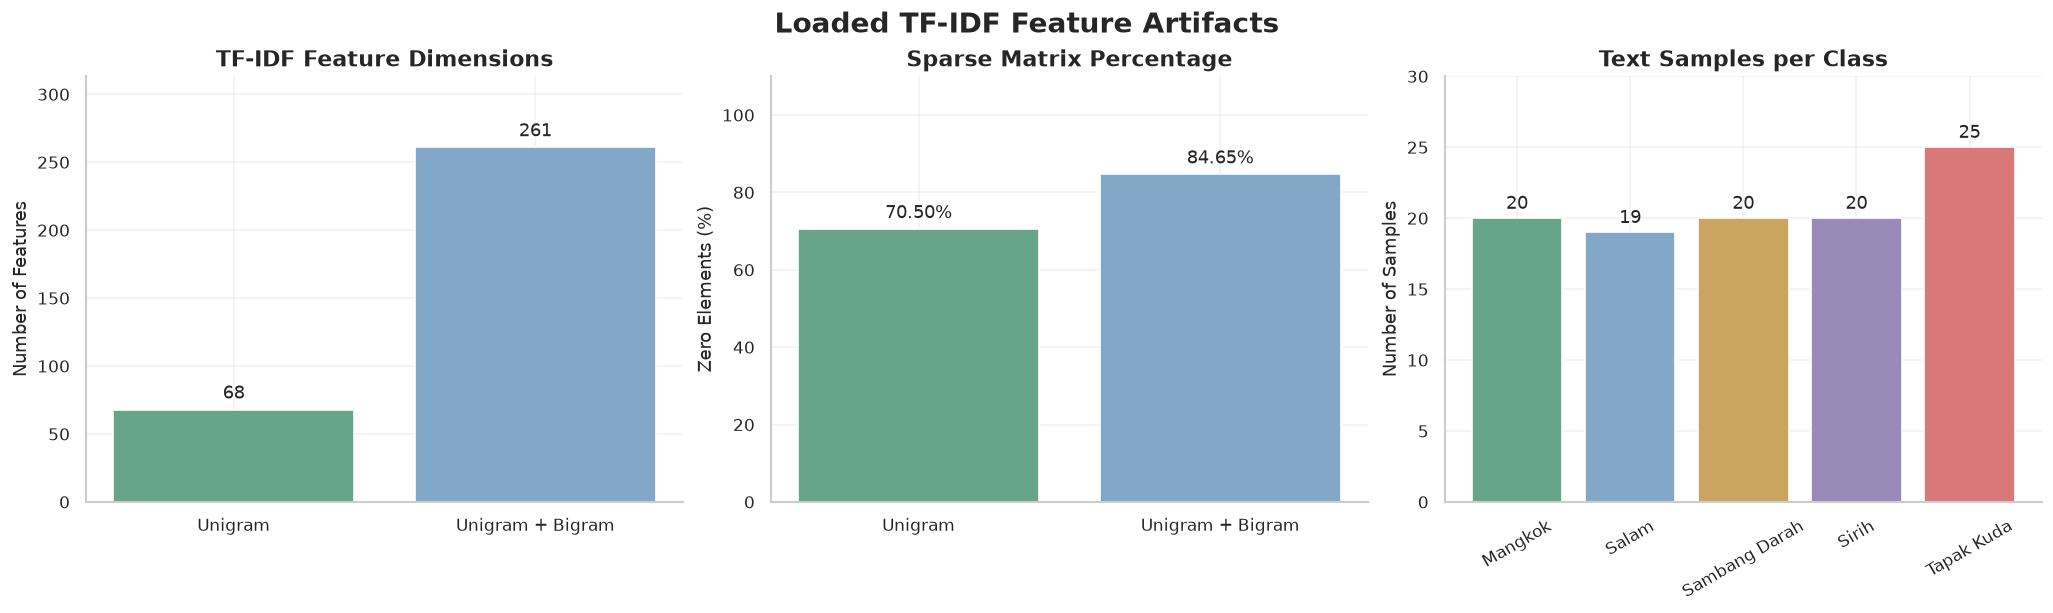

[SAVED] 106_loaded_text_feature_summary.png


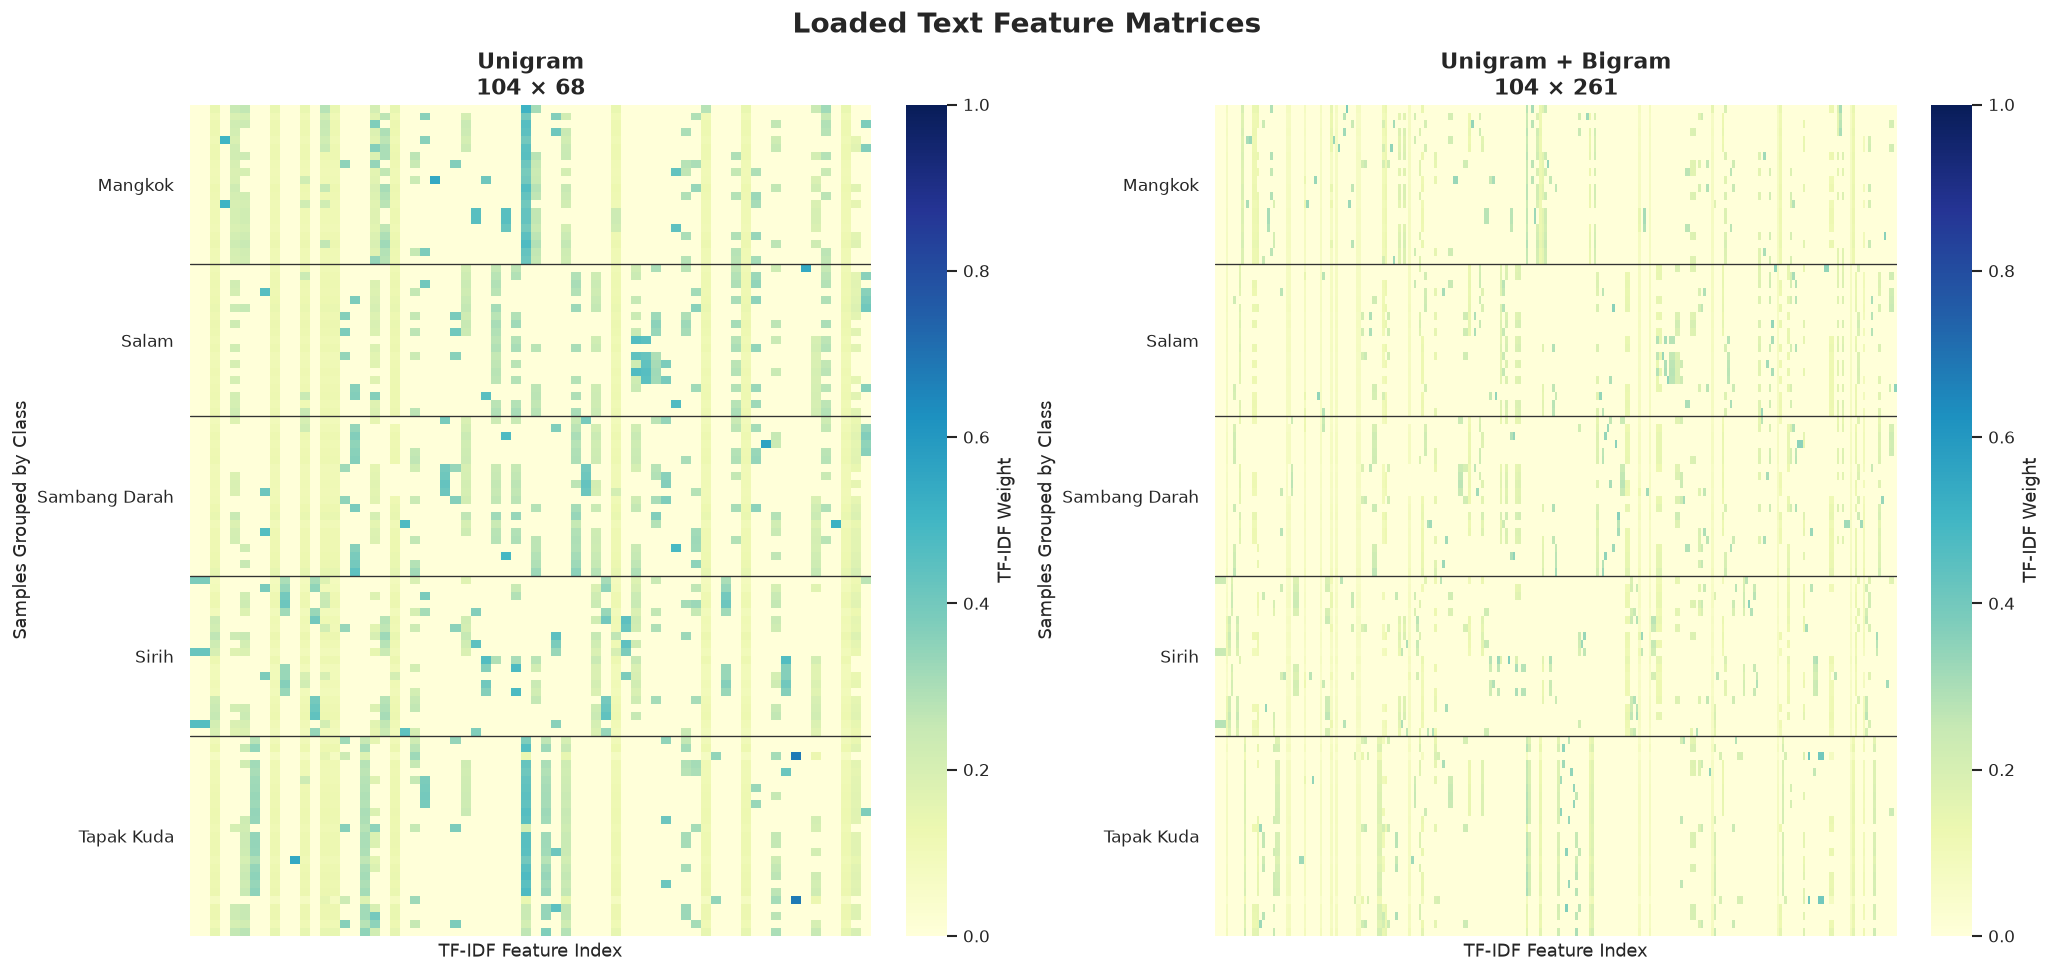

[SAVED] 107_loaded_text_feature_matrices.png

10. TEXT LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total samples,104
1,Total classes,5
2,TF-IDF configurations,2
3,Unigram matrix shape,"(104, 68)"
4,Combined matrix shape,"(104, 261)"
5,Verified payload artifacts,16
6,Aligned samples,104
7,Validation checks,80
8,Passed checks,80
9,Failed checks,0



11. SAVING TEXT LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 368_text_artifact_integrity.csv
[SAVED] 369_loaded_text_matrix_summary.csv
[SAVED] 370_text_vocabulary_integrity.csv
[SAVED] 371_text_visual_identity_alignment.csv
[SAVED] 372_text_loading_validation.csv
[SAVED] 373_loaded_text_class_distribution.csv
[SAVED] 374_text_loading_summary.csv

FINAL TEXT FEATURE LOADING SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Text samples      : 104
Visual samples    : 104
Aligned samples   : 104
Plant classes     : 5

TEXT FEATURE MATRICES
----------------------------------------------------------------------
Unigram features  : (104, 68)
Combined features : (104, 261)

ARTIFACT INFORMATION
----------------------------------------------------------------------
Verified payloads : 16/16
Loaded vectorizers: 2

VALIDATION
----------------------------------------------------------------------

In [6]:
# ============================================================
# CELL 5 - LOAD TEXT FEATURE ARTIFACTS
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

print("MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS")
print("=" * 70)

TEXT_FEATURE_LOADING_COMPLETED = False
TEXT_FEATURES_LOADED = False

# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

assert FUSION_LIBRARIES_IMPORTED is True
assert FUSION_PATH_CONFIGURATION_COMPLETED is True
assert VISUAL_FEATURE_LOADING_COMPLETED is True, (
    "Run Cell 4 successfully before Cell 5."
)

assert fusion_path_validation_df["passed"].all()
assert visual_loading_validation_df["passed"].all()

TEXT_LOADING_TOLERANCE = 1e-10
TEXT_EXPECTED_SAMPLES = 104

TEXT_EXPECTED_DIMENSIONS = {
    "Unigram": 68,
    "Unigram + Bigram": 261
}

TEXT_CONFIGURATION_ORDER = [
    "Unigram",
    "Unigram + Bigram"
]

TEXT_CONFIGURATION_COLORS = {
    "Unigram": "#66A58A",
    "Unigram + Bigram": "#83A7C7"
}

text_loading_checks = []
text_loading_figures = []

def check_text_loading(category, name, condition):
    text_loading_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition)
    })

def sha256_text_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(65536), b""):
            digest.update(chunk)
    return digest.hexdigest()

def maximum_sparse_difference(a, b):
    assert a.shape == b.shape
    delta = (a - b).tocsr()
    delta.eliminate_zeros()
    return (
        float(np.max(np.abs(delta.data)))
        if delta.nnz else 0.0
    )

print("[PASS] Previous cells validated.")


# ============================================================
# 2. PREPARE EXPECTED ARTIFACT PATHS
# ============================================================

# Use only paths established in Cell 3.
# Never load files using unvalidated paths from CSV.

text_expected_payload_paths = {}

for config_name in TEXT_CONFIGURATION_ORDER:
    for artifact_name, path in TEXT_ARTIFACT_PATHS[
        config_name
    ].items():
        text_expected_payload_paths[path.name] = path

for artifact_name, path in TEXT_SHARED_ARTIFACT_PATHS.items():
    if artifact_name != "manifest":
        text_expected_payload_paths[path.name] = path

assert len(text_expected_payload_paths) == 16
assert TEXT_MANIFEST_PATH.is_file()

print("\n1. TEXT ARTIFACT LOCATIONS")
print("-" * 70)
print("Text feature directory:", TEXT_FEATURES_DIR)
print("Expected payload files :", len(text_expected_payload_paths))
print("Manifest              :", TEXT_MANIFEST_PATH.name)


# ============================================================
# 3. LOAD AND VALIDATE TEXT MANIFEST
# ============================================================

loaded_text_manifest_df = pd.read_csv(
    TEXT_MANIFEST_PATH,
    dtype={
        "filename": str,
        "relative_path": str,
        "sha256": str
    },
    keep_default_na=False
)

manifest_columns = {
    "filename",
    "relative_path",
    "size_bytes",
    "sha256"
}

assert manifest_columns.issubset(
    loaded_text_manifest_df.columns
)

assert loaded_text_manifest_df["filename"].is_unique

expected_filenames = set(text_expected_payload_paths)
manifest_filenames = set(
    loaded_text_manifest_df["filename"]
)

assert manifest_filenames == expected_filenames, (
    "Manifest content does not match the 16 "
    "expected text payload artifacts."
)

loaded_text_manifest_df["size_bytes"] = pd.to_numeric(
    loaded_text_manifest_df["size_bytes"],
    errors="raise"
)

text_manifest_index = loaded_text_manifest_df.set_index(
    "filename"
)

check_text_loading(
    "Manifest",
    "Manifest covers all expected text artifacts",
    manifest_filenames == expected_filenames
)

print("[PASS] Text artifact manifest loaded.")


# ============================================================
# 4. VERIFY FILE INTEGRITY BEFORE JOBLIB LOADING
# ============================================================

text_artifact_integrity_records = []

print("\n2. TEXT ARTIFACT INTEGRITY")
print("-" * 70)

for filename, path in text_expected_payload_paths.items():

    manifest_row = text_manifest_index.loc[filename]

    exists = path.is_file()

    actual_size = (
        path.stat().st_size if exists else 0
    )

    actual_sha256 = (
        sha256_text_file(path) if exists else ""
    )

    expected_size = int(manifest_row["size_bytes"])

    expected_sha256 = str(
        manifest_row["sha256"]
    ).strip().lower()

    expected_relative_path = path.relative_to(
        PROJECT_ROOT
    ).as_posix()

    relative_path_match = (
        str(manifest_row["relative_path"])
        == expected_relative_path
    )

    size_match = actual_size == expected_size

    checksum_match = (
        actual_sha256 == expected_sha256
    )

    passed = (
        exists
        and actual_size > 0
        and size_match
        and checksum_match
        and relative_path_match
    )

    text_artifact_integrity_records.append({
        "filename": filename,
        "exists": exists,
        "size_bytes": actual_size,
        "size_match": size_match,
        "checksum_match": checksum_match,
        "relative_path_match": relative_path_match,
        "passed": passed
    })

    check_text_loading(
        "Artifact Integrity",
        f"{filename} integrity",
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] {filename}"
    )

text_artifact_integrity_df = pd.DataFrame(
    text_artifact_integrity_records
)

text_artifact_integrity_df.to_csv(
    METRICS_DIR / "368_text_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

# IMPORTANT: Do not unpickle Joblib files
# if their integrity check fails.
assert text_artifact_integrity_df["passed"].all(), (
    "Artifact integrity verification failed."
)

print("[PASS] 16 text payload artifacts verified.")


# ============================================================
# 5. LOAD SHARED TEXT ARTIFACTS
# ============================================================

loaded_text_sample_ids = np.asarray(
    np.load(
        TEXT_SAMPLE_IDS_PATH,
        allow_pickle=False
    ),
    dtype=str
)

loaded_text_class_labels = np.asarray(
    np.load(
        TEXT_CLASS_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=str
)

loaded_text_metadata_df = pd.read_csv(
    MULTIMODAL_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False
)

with open(
    TEXT_CORPUS_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_corpus_payload = json.load(file)

with open(
    TEXT_PREPROCESSING_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_preprocessing_config = json.load(file)

with open(
    TEXT_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_feature_config = json.load(file)

loaded_text_corpus = list(
    loaded_text_corpus_payload["descriptions"]
)

loaded_text_n_samples = len(
    loaded_text_sample_ids
)

print("\n3. SHARED TEXT ARTIFACTS")
print("-" * 70)

print("Sample IDs       :", loaded_text_sample_ids.shape)
print("Class labels     :", loaded_text_class_labels.shape)
print("Text corpus      :", len(loaded_text_corpus))
print("Metadata         :", loaded_text_metadata_df.shape)
print("Preprocessing    : Loaded")
print("Feature config   : Loaded")


# ============================================================
# 6. VALIDATE SAMPLE IDENTITIES AND METADATA
# ============================================================

assert loaded_text_n_samples == TEXT_EXPECTED_SAMPLES

assert len(loaded_text_class_labels) == (
    loaded_text_n_samples
)

assert len(loaded_text_corpus) == (
    loaded_text_n_samples
)

assert len(loaded_text_metadata_df) == (
    loaded_text_n_samples
)

assert len(np.unique(
    loaded_text_sample_ids
)) == loaded_text_n_samples

assert all(
    isinstance(doc, str) and doc.strip()
    for doc in loaded_text_corpus
)

assert loaded_text_corpus_payload[
    "sample_ids"
] == loaded_text_sample_ids.tolist()

assert loaded_text_corpus_payload[
    "number_of_documents"
] == loaded_text_n_samples

required_metadata_columns = {
    "sample_id",
    "kelas",
    "cleaned_description",
    "image_text_alignment_valid"
}

assert required_metadata_columns.issubset(
    loaded_text_metadata_df.columns
)

text_metadata_ids = (
    loaded_text_metadata_df["sample_id"]
    .to_numpy(dtype=str)
)

text_metadata_labels = (
    loaded_text_metadata_df["kelas"]
    .to_numpy(dtype=str)
)

text_metadata_corpus = (
    loaded_text_metadata_df["cleaned_description"]
    .astype(str)
    .tolist()
)

text_alignment_status = (
    loaded_text_metadata_df[
        "image_text_alignment_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

text_identity_checks = {
    "Sample IDs unique":
        len(np.unique(loaded_text_sample_ids))
        == loaded_text_n_samples,

    "Metadata sample order preserved":
        np.array_equal(
            text_metadata_ids,
            loaded_text_sample_ids
        ),

    "Metadata labels preserved":
        np.array_equal(
            text_metadata_labels,
            loaded_text_class_labels
        ),

    "Metadata descriptions preserved":
        text_metadata_corpus == loaded_text_corpus,

    "Text corpus sample IDs preserved":
        loaded_text_corpus_payload["sample_ids"]
        == loaded_text_sample_ids.tolist(),

    "Previous image-text alignment preserved":
        text_alignment_status.all(),

    "Visual and text sample IDs identical":
        np.array_equal(
            loaded_text_sample_ids,
            visual_sample_ids
        ),

    "Visual and text class labels identical":
        np.array_equal(
            loaded_text_class_labels,
            visual_labels
        )
}

text_identity_alignment_df = pd.DataFrame({
    "row_index": np.arange(loaded_text_n_samples),
    "sample_id": loaded_text_sample_ids,
    "kelas": loaded_text_class_labels,
    "visual_id_match": (
        loaded_text_sample_ids == visual_sample_ids
    ),
    "visual_label_match": (
        loaded_text_class_labels == visual_labels
    ),
    "metadata_id_match": (
        loaded_text_sample_ids == text_metadata_ids
    ),
    "metadata_label_match": (
        loaded_text_class_labels == text_metadata_labels
    ),
    "corpus_match": np.asarray([
        a == b for a, b in zip(
            loaded_text_corpus,
            text_metadata_corpus
        )
    ]),
    "alignment_flag": text_alignment_status.to_numpy()
})

alignment_columns = [
    "visual_id_match",
    "visual_label_match",
    "metadata_id_match",
    "metadata_label_match",
    "corpus_match",
    "alignment_flag"
]

text_identity_alignment_df["passed"] = (
    text_identity_alignment_df[
        alignment_columns
    ].all(axis=1)
)

for name, passed in text_identity_checks.items():
    check_text_loading("Sample Alignment", name, passed)

check_text_loading(
    "Sample Alignment",
    "All 104 sample-level alignment records passed",
    text_identity_alignment_df["passed"].all()
)

assert all(text_identity_checks.values()), (
    "Text and visual sample identity mismatch."
)

print("\n4. TEXT-VISUAL SAMPLE ALIGNMENT")
print("-" * 70)

print(
    "Aligned samples:",
    int(text_identity_alignment_df["passed"].sum()),
    "/",
    loaded_text_n_samples
)

display(text_identity_alignment_df.head(8))


# ============================================================
# 7. LOAD TF-IDF MATRICES AND VECTORIZERS
# ============================================================

loaded_text_vectorizers = {}
loaded_text_feature_matrices = {}
loaded_text_feature_names = {}
loaded_text_idf_weights = {}
loaded_text_vocabulary_reports = {}

text_matrix_summary_records = []
text_vocabulary_validation_records = []

print("\n5. LOADING TF-IDF CONFIGURATIONS")
print("-" * 70)

for configuration_name in TEXT_CONFIGURATION_ORDER:

    artifact_paths = TEXT_ARTIFACT_PATHS[
        configuration_name
    ]

    vectorizer = joblib.load(
        artifact_paths["vectorizer"]
    )

    feature_matrix = load_npz(
        artifact_paths["matrix"]
    ).tocsr()

    feature_names = np.load(
        artifact_paths["feature_names"],
        allow_pickle=False
    )

    idf_weights = np.load(
        artifact_paths["idf_weights"],
        allow_pickle=False
    )

    vocabulary_df = pd.read_csv(
        artifact_paths["vocabulary"],
        dtype={"term": str},
        keep_default_na=False,
        float_precision="round_trip"
    )

    loaded_text_vectorizers[
        configuration_name
    ] = vectorizer

    loaded_text_feature_matrices[
        configuration_name
    ] = feature_matrix

    loaded_text_feature_names[
        configuration_name
    ] = feature_names

    loaded_text_idf_weights[
        configuration_name
    ] = idf_weights

    loaded_text_vocabulary_reports[
        configuration_name
    ] = vocabulary_df

    expected_dimension = (
        TEXT_EXPECTED_DIMENSIONS[configuration_name]
    )

    expected_ngram_range = (
        (1, 1)
        if configuration_name == "Unigram"
        else (1, 2)
    )

    # ----------------------------------------------
    # A. Verify matrix properties
    # ----------------------------------------------

    row_norms = np.sqrt(
        np.asarray(
            feature_matrix.multiply(
                feature_matrix
            ).sum(axis=1)
        ).ravel()
    )

    matrix_checks = {
        "Matrix shape":
            feature_matrix.shape
            == (
                TEXT_EXPECTED_SAMPLES,
                expected_dimension
            ),

        "CSR sparse format":
            issparse(feature_matrix)
            and feature_matrix.format == "csr",

        "Float64 dtype":
            feature_matrix.dtype == np.float64,

        "Finite matrix values":
            np.isfinite(
                feature_matrix.data
            ).all(),

        "Nonnegative TF-IDF weights":
            np.all(
                feature_matrix.data >= 0
            ),

        "No zero document vectors":
            np.all(
                row_norms > 0
            ),

        "Unit L2 row normalization":
            np.allclose(
                row_norms,
                1.0,
                atol=TEXT_LOADING_TOLERANCE,
                rtol=0
            )
    }

    # ----------------------------------------------
    # B. Verify vectorizer properties
    # ----------------------------------------------

    vectorizer_feature_names = (
        vectorizer.get_feature_names_out()
    )

    vectorizer_checks = {
        "TF-IDF vectorizer type":
            isinstance(
                vectorizer,
                TfidfVectorizer
            ),

        "Vectorizer fitted":
            hasattr(vectorizer, "vocabulary_")
            and hasattr(vectorizer, "idf_"),

        "N-gram configuration":
            vectorizer.ngram_range
            == expected_ngram_range,

        "Vectorizer uses L2":
            vectorizer.norm == "l2",

        "Vocabulary dimension":
            len(vectorizer.vocabulary_)
            == expected_dimension,

        "Saved feature names identical":
            np.array_equal(
                feature_names,
                vectorizer_feature_names
            ),

        "Saved IDF weights identical":
            np.array_equal(
                idf_weights,
                vectorizer.idf_
            ),

        "IDF values finite and positive":
            np.isfinite(idf_weights).all()
            and np.all(idf_weights > 0)
    }

    # ----------------------------------------------
    # C. Verify vocabulary report
    # ----------------------------------------------

    vocabulary_required_columns = {
        "feature_index",
        "term",
        "ngram_type",
        "document_frequency",
        "idf_weight"
    }

    assert vocabulary_required_columns.issubset(
        vocabulary_df.columns
    )

    report_indices = pd.to_numeric(
        vocabulary_df["feature_index"],
        errors="raise"
    ).to_numpy()

    actual_document_frequency = np.asarray(
        (feature_matrix != 0).sum(axis=0)
    ).ravel()

    vocabulary_checks = {
        "Vocabulary report length":
            len(vocabulary_df)
            == expected_dimension,

        "Feature indices sequential":
            np.array_equal(
                report_indices,
                np.arange(expected_dimension)
            ),

        "Vocabulary terms match":
            np.array_equal(
                vocabulary_df["term"]
                .to_numpy(dtype=str),
                vectorizer_feature_names
            ),

        "Vocabulary IDF matches":
            np.allclose(
                vocabulary_df["idf_weight"]
                .to_numpy(dtype=float),
                idf_weights,
                atol=TEXT_LOADING_TOLERANCE,
                rtol=0
            ),

        "Document frequency matches":
            np.array_equal(
                vocabulary_df["document_frequency"]
                .to_numpy(dtype=int),
                actual_document_frequency
            ),

        "Vocabulary index mapping matches":
            all(
                vectorizer.vocabulary_.get(
                    term
                ) == index
                for index, term in enumerate(
                    vectorizer_feature_names
                )
            )
    }

    # ----------------------------------------------
    # D. Reproduce reference matrix
    # ----------------------------------------------

    reproduced_matrix = (
        vectorizer.transform(
            loaded_text_corpus
        ).tocsr()
    )

    reproduction_difference = (
        maximum_sparse_difference(
            reproduced_matrix,
            feature_matrix
        )
    )

    check_text_loading(
        configuration_name,
        "Reference matrix reproduced by transform()",
        reproduction_difference
        <= TEXT_LOADING_TOLERANCE
    )

    for checks in [
        matrix_checks,
        vectorizer_checks,
        vocabulary_checks
    ]:
        for name, passed in checks.items():
            check_text_loading(
                configuration_name,
                name,
                passed
            )

    # ----------------------------------------------
    # E. Save matrix statistics
    # ----------------------------------------------

    total_elements = (
        feature_matrix.shape[0]
        * feature_matrix.shape[1]
    )

    nonzero_values = int(
        feature_matrix.count_nonzero()
    )

    unigram_features = int(sum(
        " " not in term
        for term in vectorizer_feature_names
    ))

    bigram_features = int(sum(
        " " in term
        for term in vectorizer_feature_names
    ))

    text_matrix_summary_records.append({
        "configuration": configuration_name,
        "samples": feature_matrix.shape[0],
        "feature_dimension": feature_matrix.shape[1],
        "unigram_features": unigram_features,
        "bigram_features": bigram_features,
        "nonzero_values": nonzero_values,
        "zero_values": (
            total_elements - nonzero_values
        ),
        "sparsity_percent": (
            100 * (1 - nonzero_values / total_elements)
        ),
        "minimum_l2_norm": float(
            row_norms.min()
        ),
        "maximum_l2_norm": float(
            row_norms.max()
        ),
        "reproduction_max_difference": (
            reproduction_difference
        ),
        "matrix_file_kib": (
            artifact_paths["matrix"].stat().st_size
            / 1024
        ),
        "vectorizer_file_kib": (
            artifact_paths["vectorizer"].stat().st_size
            / 1024
        )
    })

    text_vocabulary_validation_records.append({
        "configuration": configuration_name,
        "vocabulary_size": len(
            vectorizer.vocabulary_
        ),
        "feature_names_match": (
            vectorizer_checks[
                "Saved feature names identical"
            ]
        ),
        "idf_match": (
            vectorizer_checks[
                "Saved IDF weights identical"
            ]
        ),
        "document_frequency_match": (
            vocabulary_checks[
                "Document frequency matches"
            ]
        ),
        "reference_matrix_reproduced": (
            reproduction_difference
            <= TEXT_LOADING_TOLERANCE
        )
    })

    print(f"\nConfiguration: {configuration_name}")
    print("Matrix shape :", feature_matrix.shape)
    print("Nonzero      :", nonzero_values)
    print("Unigram      :", unigram_features)
    print("Bigram       :", bigram_features)
    print(
        "Reproduction difference:",
        f"{reproduction_difference:.3e}"
    )

text_loaded_matrix_summary_df = pd.DataFrame(
    text_matrix_summary_records
)

text_vocabulary_integrity_df = pd.DataFrame(
    text_vocabulary_validation_records
)

print("\n6. LOADED TEXT MATRIX SUMMARY")
print("-" * 70)

display(
    text_loaded_matrix_summary_df.round(6)
)


# ============================================================
# 8. CREATE MAIN TEXT FEATURE VARIABLES
# ============================================================

tfidf_unigram_vectorizer = (
    loaded_text_vectorizers["Unigram"]
)

tfidf_combined_vectorizer = (
    loaded_text_vectorizers["Unigram + Bigram"]
)

tfidf_unigram_features = (
    loaded_text_feature_matrices["Unigram"]
)

tfidf_combined_features = (
    loaded_text_feature_matrices["Unigram + Bigram"]
)

text_feature_matrices = (
    loaded_text_feature_matrices
)

text_vectorizers = (
    loaded_text_vectorizers
)

text_sample_ids = (
    loaded_text_sample_ids
)

text_labels = (
    loaded_text_class_labels
)

text_corpus = (
    loaded_text_corpus
)

text_n_samples = (
    len(text_sample_ids)
)

text_class_names = sorted(
    np.unique(text_labels)
)

print("\n7. MAIN TEXT FEATURE VARIABLES")
print("-" * 70)

print("Unigram features :", tfidf_unigram_features.shape)
print("Combined features:", tfidf_combined_features.shape)
print("Text sample IDs  :", text_sample_ids.shape)
print("Text labels      :", text_labels.shape)


# ============================================================
# 9. CLASS DISTRIBUTION
# ============================================================

text_loaded_class_summary_df = (
    pd.Series(text_labels, name="kelas")
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

text_loaded_class_summary_df["percentage"] = (
    100
    * text_loaded_class_summary_df["number_of_samples"]
    / text_n_samples
)

expected_class_counts = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

actual_class_counts = dict(zip(
    text_loaded_class_summary_df["kelas"],
    text_loaded_class_summary_df["number_of_samples"]
))

check_text_loading(
    "Class Distribution",
    "Five-class distribution preserved",
    actual_class_counts == expected_class_counts
)

print("\n8. CLASS DISTRIBUTION")
print("-" * 70)

display(
    text_loaded_class_summary_df.round(4)
)


# ============================================================
# 10. FEATURE CONFIGURATION VALIDATION
# ============================================================

saved_configurations = loaded_text_feature_config.get(
    "configurations",
    {}
)

for configuration_name in TEXT_CONFIGURATION_ORDER:

    assert configuration_name in saved_configurations

    saved_info = saved_configurations[
        configuration_name
    ]

    loaded_matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} feature dimension",
        int(saved_info["feature_dimension"])
        == loaded_matrix.shape[1]
    )

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} matrix shape",
        tuple(saved_info["matrix_shape"])
        == loaded_matrix.shape
    )

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} nonzero count",
        int(saved_info["nonzero_values"])
        == loaded_matrix.nnz
    )

check_text_loading(
    "Saved Configuration",
    "Sample count preserved",
    loaded_text_feature_config[
        "number_of_samples"
    ] == text_n_samples
)

check_text_loading(
    "Saved Configuration",
    "Reference-only evaluation requirement preserved",
    loaded_text_feature_config[
        "evaluation_requires_reference_only_refit"
    ] is True
)

check_text_loading(
    "Saved Configuration",
    "No final text configuration selected",
    loaded_text_feature_config[
        "final_text_configuration_selected"
    ] is False
)


# ============================================================
# 11. FINAL TEXT LOADING VALIDATION
# ============================================================

text_loading_validation_df = pd.DataFrame(
    text_loading_checks
)

text_loading_validation_df["status"] = np.where(
    text_loading_validation_df["passed"],
    "Passed",
    "Failed"
)

text_loading_total_checks = len(
    text_loading_validation_df
)

text_loading_passed_checks = int(
    text_loading_validation_df["passed"].sum()
)

text_loading_failed_checks = (
    text_loading_total_checks
    - text_loading_passed_checks
)

print("\n9. TEXT FEATURE LOADING VALIDATION")
print("-" * 70)

display(text_loading_validation_df)

assert text_loading_validation_df["passed"].all(), (
    text_loading_validation_df.loc[
        ~text_loading_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All text loading checks passed.")


# ============================================================
# 12. VISUALIZATION — TEXT FEATURE SUMMARY
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

plot_df = (
    text_loaded_matrix_summary_df
    .set_index("configuration")
    .loc[TEXT_CONFIGURATION_ORDER]
)

colors = [
    TEXT_CONFIGURATION_COLORS[name]
    for name in TEXT_CONFIGURATION_ORDER
]

# A. Feature dimensions.

bars = axes[0].bar(
    TEXT_CONFIGURATION_ORDER,
    plot_df["feature_dimension"],
    color=colors
)

axes[0].bar_label(bars, padding=4)
axes[0].set_title("TF-IDF Feature Dimensions")
axes[0].set_ylabel("Number of Features")
axes[0].margins(y=0.2)

# B. Matrix sparsity.

bars = axes[1].bar(
    TEXT_CONFIGURATION_ORDER,
    plot_df["sparsity_percent"],
    color=colors
)

axes[1].bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

axes[1].set_ylim(0, 110)
axes[1].set_title("Sparse Matrix Percentage")
axes[1].set_ylabel("Zero Elements (%)")

# C. Class distribution.

class_colors = [
    CLASS_COLORS.get(name, "#83A7C7")
    for name in text_loaded_class_summary_df["kelas"]
]

bars = axes[2].bar(
    text_loaded_class_summary_df["kelas"],
    text_loaded_class_summary_df["number_of_samples"],
    color=class_colors
)

axes[2].bar_label(bars, padding=3)
axes[2].tick_params(axis="x", rotation=30)
axes[2].set_title("Text Samples per Class")
axes[2].set_ylabel("Number of Samples")
axes[2].margins(y=0.2)

fig.suptitle(
    "Loaded TF-IDF Feature Artifacts",
    fontsize=17,
    fontweight="bold"
)

figure_path = (
    FUSION_FIGURES_DIR
    / "106_loaded_text_feature_summary.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_loading_figures.append(figure_path)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 13. VISUALIZATION — TF-IDF FEATURE MATRICES
# ============================================================

plot_order = np.argsort(
    text_labels,
    kind="stable"
)

sorted_labels = text_labels[plot_order]

class_boundaries = np.flatnonzero(
    sorted_labels[1:] != sorted_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]
class_ends = np.r_[
    class_boundaries,
    text_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    TEXT_CONFIGURATION_ORDER
):

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    # Dense conversion is for plotting only.
    # Stored matrices remain sparse CSR.
    plot_matrix = matrix[plot_order].toarray()

    sns.heatmap(
        plot_matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={"label": "TF-IDF Weight"},
        ax=ax
    )

    for boundary in class_boundaries:
        ax.axhline(
            boundary,
            color="#333333",
            linewidth=0.8
        )

    ax.set_yticks(class_centers)

    ax.set_yticklabels(
        sorted_labels[class_starts],
        rotation=0
    )

    ax.set_title(
        f"{configuration_name}\n"
        f"{matrix.shape[0]} × {matrix.shape[1]}"
    )

    ax.set_xlabel("TF-IDF Feature Index")
    ax.set_ylabel("Samples Grouped by Class")

fig.suptitle(
    "Loaded Text Feature Matrices",
    fontsize=17,
    fontweight="bold"
)

figure_path = (
    FUSION_FIGURES_DIR
    / "107_loaded_text_feature_matrices.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_loading_figures.append(figure_path)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 14. CREATE FINAL LOADING SUMMARY
# ============================================================

text_loading_summary_df = pd.DataFrame([
    ("Total samples", text_n_samples),
    ("Total classes", len(text_class_names)),
    ("TF-IDF configurations", len(text_vectorizers)),
    ("Unigram matrix shape", str(tfidf_unigram_features.shape)),
    ("Combined matrix shape", str(tfidf_combined_features.shape)),
    ("Verified payload artifacts", int(
        text_artifact_integrity_df["passed"].sum()
    )),
    ("Aligned samples", int(
        text_identity_alignment_df["passed"].sum()
    )),
    ("Validation checks", text_loading_total_checks),
    ("Passed checks", text_loading_passed_checks),
    ("Failed checks", text_loading_failed_checks),
    ("Generated figures", len(text_loading_figures)),
    ("Vectorizers refitted", False),
    ("Sample order modified", False),
    ("Text configuration selected", False),
    ("Independent evaluation completed", False),
    ("Ready for multimodal validation", True)
], columns=["Indicator", "Result"])

print("\n10. TEXT LOADING SUMMARY")
print("-" * 70)

display(text_loading_summary_df)


# ============================================================
# 15. SAVE CELL 5 REPORTS
# ============================================================

text_loading_reports = {
    "368_text_artifact_integrity.csv":
        text_artifact_integrity_df,

    "369_loaded_text_matrix_summary.csv":
        text_loaded_matrix_summary_df,

    "370_text_vocabulary_integrity.csv":
        text_vocabulary_integrity_df,

    "371_text_visual_identity_alignment.csv":
        text_identity_alignment_df,

    "372_text_loading_validation.csv":
        text_loading_validation_df,

    "373_loaded_text_class_distribution.csv":
        text_loaded_class_summary_df,

    "374_text_loading_summary.csv":
        text_loading_summary_df
}

print("\n11. SAVING TEXT LOADING REPORTS")
print("-" * 70)

for filename, dataframe in text_loading_reports.items():

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert text_artifact_integrity_df["passed"].all()
assert text_loading_validation_df["passed"].all()
assert text_identity_alignment_df["passed"].all()

assert tfidf_unigram_features.shape == (104, 68)
assert tfidf_combined_features.shape == (104, 261)

assert np.array_equal(
    text_sample_ids,
    visual_sample_ids
)

assert np.array_equal(
    text_labels,
    visual_labels
)

assert len(text_loading_figures) == 2

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in text_loading_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in text_loading_reports
)

TEXT_FEATURE_LOADING_COMPLETED = True
TEXT_FEATURES_LOADED = True


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEXT FEATURE LOADING SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)
print(f"Text samples      : {text_n_samples}")
print(f"Visual samples    : {len(visual_sample_ids)}")
print(f"Aligned samples   : {text_identity_alignment_df['passed'].sum()}")
print(f"Plant classes     : {len(text_class_names)}")

print("\nTEXT FEATURE MATRICES")
print("-" * 70)
print("Unigram features  :", tfidf_unigram_features.shape)
print("Combined features :", tfidf_combined_features.shape)

print("\nARTIFACT INFORMATION")
print("-" * 70)
print(
    "Verified payloads :",
    f"{text_artifact_integrity_df['passed'].sum()}/"
    f"{len(text_artifact_integrity_df)}"
)
print("Loaded vectorizers:", len(loaded_text_vectorizers))

print("\nVALIDATION")
print("-" * 70)
print(
    "Technical checks  :",
    f"{text_loading_passed_checks}/{text_loading_total_checks}"
)
print("Failed checks     :", text_loading_failed_checks)
print("Generated reports :", len(text_loading_reports))
print("Generated figures :", len(text_loading_figures))

print("\n[PASS] Both TF-IDF matrices loaded.")
print("[PASS] Both fitted vectorizers loaded.")
print("[PASS] Vocabulary and IDF preserved.")
print("[PASS] Original corpus reproduced.")
print("[PASS] Text and visual samples aligned.")
print("[PASS] Sparse CSR and L2 normalization validated.")
print("[PASS] Artifact integrity verified.")
print("[PASS] No vectorizers were refitted.")

print("\n" + "=" * 70)
print("TEXT FEATURE LOADING COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 6 - Multimodal Dataset Validation")